# Identity Resolution Matcher - Wikidata x OurAirports (Machine Learning)

### Purpose

Train and apply a machine-learning-based matcher between Wikidata and OurAirports airport records. The gold standard produced in `create_gold_standard.ipynb` (`gold_standard_wd_oa.csv`) is used as labeled training/validation/test data. Instead of the single hand-weighted similarity score used for ranking in the gold-standard notebook, a learned classifier combines multiple features into a match decision. The trained matcher is then applied to the full Wikidata x OurAirports candidate space to produce the final correspondences.

### Methods

1. **Load gold standard**: read `gold_standard_wd_oa.csv` and keep its existing `split` (train/val 70 % vs. test 30 %, held out until the final evaluation) and `fold` (5 stratified folds) columns.
2. **Feature engineering**: build similarity features per shared column (`name`, `city`, `countryName`, `countryCode`, `localCode`, `elevation`, `lat`/`lon`) using PyDI's `FeatureExtractor`. `icao`/`iata` stay out entirely - they are the identifiers used to build the gold standard's labels, so using them as features would leak the label.
3. **Model training & tuning**: train and tune four classifiers - Logistic Regression, SVM, Random Forest, XGBoost - with `GridSearchCV` over the existing `fold` column via `PredefinedSplit`, so every model is tuned and compared on the exact same 5 folds; standardize features for Logistic Regression/SVM, leave Random Forest/XGBoost unscaled.
4. **Evaluation**: compare the four models on the held-out test split (precision, recall, F1, ROC/PR curves, confusion matrix), with a separate breakdown by pair type.
5. **Error analysis**: inspect misclassified hard pairs to understand failure modes, mirroring the manual-inspection approach from the gold-standard notebook.
6. **Cluster analysis and one-to-one matching**: group the above-threshold pairs from step 7 into connected components (union-find) to detect conflicts - the same WD or OA record matched to more than one record on the other side. A manual sample of clusters with 3-4 records showed that most of the extra links are wrong (the same few airports linked to neighbouring ones), so the final correspondences are selected by global one-to-one matching (PyDI's `GreedyOneToOneMatchingAlgorithm`: pairs sorted by score, a pair is kept only if neither record is already used), the same method as in the OurAirports x Kaggle matcher. Each pair keeps its score and the id of the cluster it came from. The result is saved as the final correspondences.
7. **Apply the matcher**: block the full Wikidata x OurAirports datasets (Rules A and B as in the gold-standard notebook, with a coarser grid for Rule B, plus Rule C on the city), extract the same features for all candidate pairs, and score them with the best-performing model.
   - **Blocking key selection**: measure the blocking configuration actually used (Rule A union Rule B union Rule C, deduplicated) against a full-scale ground-truth proxy built from ICAO/IATA matches, using Pair Completeness / recall = (positives still co-blocked) / (total positives) and Reduction Ratio = 1 - (candidate pairs) / (|WD| x |OA|). Target: recall > 97 %.
   - **Threshold**: chosen by cross-validation on the train/validation folds: among the thresholds whose CV F1 is within 0.01 of the best, the one with the fewest records matched more than once. Pairs with a missing coordinate are never accepted automatically: their distance is unknown and the gold standard has too few such pairs to teach the model.
8. **End-to-end evaluation**: the final correspondences are checked against the gold standard test split (a test positive missing from the output is a false negative, a test negative in the output is a false positive) before and after the one-to-one selection.


## 1. Load Gold Standard

Load the Wikidata and OurAirports normalized records (needed later for feature extraction, since the gold standard only stores `id1`/`id2`), and the labeled pairs from `create_gold_standard.ipynb`. The `split` column (`train_val` / `test`) and `fold` column (5 stratified folds within `train_val`) produced there are kept as-is: `test` is set aside untouched until the final evaluation, and `fold` is used for cross-validation during model training and tuning.

In [1]:
import pandas as pd
from pathlib import Path
from PyDI.io import load_csv

DATA_DIR = Path("../../../data/normalized_outputs")
GOLD_STANDARD_DIR = Path("../../../data/identity_resolution/gold_standard")

WIKIDATA_FILE = DATA_DIR / "wikidataNormalized.csv"
OURAIRPORT_FILE = DATA_DIR / "ourairportsNormalized.csv"
GOLD_STANDARD_FILE = GOLD_STANDARD_DIR / "gold_standard_wd_oa.csv"

df_wd = load_csv(WIKIDATA_FILE, name="wikidata")
df_wd.attrs["source"] = "wikidata"

df_oa = load_csv(OURAIRPORT_FILE, name="ourairports")
df_oa.attrs["source"] = "ourairports"

gold = pd.read_csv(GOLD_STANDARD_FILE)

print(f"Wikidata records: {len(df_wd):,}")
print(f"OurAirports records: {len(df_oa):,}")
print(f"Gold standard pairs: {len(gold):,}")
display(gold.head(3))

# test is held out untouched until the final evaluation (step 4)
train_val = gold[gold["split"] == "train_val"].copy()
test = gold[gold["split"] == "test"].copy()

print(f"\ntrain_val: {len(train_val):,} pairs, fold distribution:")
print(train_val["fold"].value_counts().sort_index())

print(f"\ntest (held out): {len(test):,} pairs")

print("\ntrain_val pairs by type:")
print(train_val["type"].value_counts())

Wikidata records: 24,859
OurAirports records: 86,151
Gold standard pairs: 1,210


,id1,id2,score,type,label,split,fold
0,wd_5221,oa_30703,0.289489,hard positive,1,train_val,1.0
1,wd_6251,oa_28495,0.306685,hard positive,1,train_val,1.0
2,wd_7518,oa_63370,0.340768,hard positive,1,train_val,0.0



train_val: 847 pairs, fold distribution:
fold
0.0    170
1.0    170
2.0    169
3.0    169
4.0    169
Name: count, dtype: int64

test (held out): 363 pairs

train_val pairs by type:
type
hard positive            175
normal positive          175
hard negative            175
normal negative          175
heliport negative         93
code changed positive     48
heliport positive          6
Name: count, dtype: int64


## 2. Feature Engineering

Build the comparator set used to turn each candidate pair into a feature vector. `icao` is excluded entirely (it is the identifier used to construct the gold standard's labels, so using it as a feature would leak the label). `iata` is left out for now as well. One cell per shared column states which similarity method(s) are used and why, then instantiates the comparators for that column.

### `name`

- Edit-based (char-level): `levenshtein`, `jaro`, `jaro_winkler`, `strcmp95`
- Token-based (word): `jaccard`, `sorensen_dice`, `overlap`, `cosine`
- Token-based (n-gram, tolerates typos the word-level tokenizer misses): `jaccard` (bigram), `cosine` (trigram)
- Containment: does one name fully contain the other (abbreviation / short-vs-long name, e.g. `wamba airport` vs. `kikongo sur wamba airport`)
- Monge-Elkan: for each word in one name, take its best (max) Jaro-Winkler match among the words in the other name, average, then average both directions. Catches reordered/partial name overlaps (e.g. "springfield international airport" vs. "international airport of springfield") that whole-string edit-based methods miss. PyDI's built-in `monge_elkan` option is not usable directly (it returns unnormalized scores), so this is a custom comparator.
- Extended (generalized) Jaccard on TF-IDF-weighted term vectors: `J(a, b) = (a . b) / (||a||^2 + ||b||^2 - a . b)`. Unlike the set-based `jaccard` above, this down-weights common tokens (e.g. "airport") via TF-IDF instead of treating every shared word equally, and is order-invariant like the set-based version.
- Soundex (phonetic, English-oriented) and Koelner Phonetik (phonetic, German-oriented): encode each word to a phonetic code, then take the Jaccard overlap of the code sets of the two names. Catches same-sounding, differently-spelled names. jellyfish provides `soundex`; Koelner Phonetik has no library implementation available here, so it is implemented from the standard rule table.

In [2]:
from PyDI.entitymatching import StringComparator, NumericComparator, BaseComparator
from PyDI.utils import SimilarityRegistry
import re
import jellyfish
from sklearn.feature_extraction.text import TfidfVectorizer


class ContainmentComparator(BaseComparator):
    """1.0 if one string is fully contained in the other (case-insensitive), else 0.0."""

    def __init__(self, column):
        super().__init__(name=f"ContainmentComparator({column})")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        a, b = v1.strip().lower(), v2.strip().lower()
        if not a or not b:
            return 0.0
        return 1.0 if (a in b or b in a) else 0.0




class MongeElkanComparator(BaseComparator):
    """Monge-Elkan similarity: for each token in one name, take the best (max) inner
    similarity to any token in the other name, average, then average both directions
    (symmetric). Uses Jaro-Winkler as the inner token similarity, so the result stays in [0, 1]."""

    def __init__(self, column="name", inner_similarity="jaro_winkler"):
        super().__init__(name=f"MongeElkanComparator({column})")
        self.column = column
        self._inner = SimilarityRegistry.get_function(inner_similarity, "char")

    def _tokens(self, value):
        return [t for t in str(value).strip().lower().split() if t]

    def _directional(self, tokens1, tokens2):
        return sum(max(self._inner(t1, t2) for t2 in tokens2) for t1 in tokens1) / len(tokens1)

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        tokens1, tokens2 = self._tokens(v1), self._tokens(v2)
        if not tokens1 or not tokens2:
            return 0.0
        return (self._directional(tokens1, tokens2) + self._directional(tokens2, tokens1)) / 2


_name_tfidf_vectorizer = TfidfVectorizer().fit(
    pd.concat([df_wd["name"], df_oa["name"]]).dropna().astype(str)
)


class ExtendedJaccardComparator(BaseComparator):
    """Generalized Jaccard on TF-IDF-weighted term vectors:
    J(a, b) = (a . b) / (||a||^2 + ||b||^2 - a . b)."""

    def __init__(self, column, vectorizer):
        super().__init__(name=f"ExtendedJaccardComparator({column})")
        self.column = column
        self.vectorizer = vectorizer

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        a, b = self.vectorizer.transform([v1, v2])
        dot = a.multiply(b).sum()
        denom = a.multiply(a).sum() + b.multiply(b).sum() - dot
        return float(dot / denom) if denom > 0 else 0.0


def koelner_phonetik(word):
    """Koelner Phonetik (Cologne phonetics): German phonetic code, standard rule table
    (see Wikipedia "Koelner Phonetik"). No ready-made implementation was available, so
    this follows the published letter-to-digit rules directly."""
    word = re.sub(r"[^A-ZÄÖÜß]", "", word.upper())
    if not word:
        return ""
    codes, n = [], len(word)
    for i, ch in enumerate(word):
        prev = word[i - 1] if i > 0 else ""
        nxt = word[i + 1] if i < n - 1 else ""
        if ch in "AEIJOUYÄÖÜ":
            codes.append("0")
        elif ch == "B":
            codes.append("1")
        elif ch == "P":
            codes.append("3" if nxt == "H" else "1")
        elif ch in "DT":
            codes.append("8" if nxt in "CSZ" else "2")
        elif ch in "FVW":
            codes.append("3")
        elif ch in "GKQ":
            codes.append("4")
        elif ch == "C":
            if i == 0:
                codes.append("4" if nxt in "AHKLOQRUX" else "8")
            elif prev in "SZ":
                codes.append("8")
            else:
                codes.append("4" if nxt in "AHKOQUX" else "8")
        elif ch == "X":
            codes.append("8" if prev in "CKQ" else "48")
        elif ch == "L":
            codes.append("5")
        elif ch in "MN":
            codes.append("6")
        elif ch == "R":
            codes.append("7")
        elif ch in "SZß":
            codes.append("8")
        else:
            codes.append("")
    raw = "".join(codes)
    if not raw:
        return ""
    collapsed = raw[0]
    for d in raw[1:]:
        if d != collapsed[-1]:
            collapsed += d
    return collapsed[0] + collapsed[1:].replace("0", "")


class PhoneticOverlapComparator(BaseComparator):
    """Jaccard overlap between the sets of per-word phonetic codes of the two names."""

    def __init__(self, column, phonetic_fn, fn_name):
        super().__init__(name=f"PhoneticOverlapComparator({column}, {fn_name})")
        self.column = column
        self.phonetic_fn = phonetic_fn

    def _codes(self, value):
        codes = set()
        for token in str(value).split():
            code = self.phonetic_fn(token)
            if code:
                codes.add(code)
        return codes

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        c1, c2 = self._codes(v1), self._codes(v2)
        if not c1 or not c2:
            return 0.0
        return len(c1 & c2) / len(c1 | c2)


name_comparators = [
    # edit-based (char-level)
    StringComparator(column="name", similarity_function="levenshtein"),
    StringComparator(column="name", similarity_function="jaro"),
    StringComparator(column="name", similarity_function="jaro_winkler"),
    StringComparator(column="name", similarity_function="strcmp95"),
    # token-based (word)
    StringComparator(column="name", similarity_function="jaccard", tokenization="word"),
    StringComparator(column="name", similarity_function="sorensen_dice", tokenization="word"),
    StringComparator(column="name", similarity_function="overlap", tokenization="word"),
    StringComparator(column="name", similarity_function="cosine", tokenization="word"),
    # token-based (n-gram)
    StringComparator(column="name", similarity_function="jaccard", tokenization="ngram_2"),
    StringComparator(column="name", similarity_function="cosine", tokenization="ngram_3"),
    # containment
    ContainmentComparator(column="name"),
    MongeElkanComparator(column="name"),
    ExtendedJaccardComparator(column="name", vectorizer=_name_tfidf_vectorizer),
    PhoneticOverlapComparator(column="name", phonetic_fn=jellyfish.soundex, fn_name="soundex"),
    PhoneticOverlapComparator(column="name", phonetic_fn=koelner_phonetik, fn_name="koelner_phonetik"),
]

print(f"{len(name_comparators)} comparators for `name`")

/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


15 comparators for `name`


### `name` (embedding similarity)

Sentence-embedding cosine similarity on `name`, using PyDI's `VectorFeatureExtractor` (sentence-transformers under the hood). This is not a `BaseComparator`, so it is not part of `name_comparators` / `comparators` above - it produces its own feature column(s) directly from `df_left`/`df_right`/pairs, to be concatenated with the comparator-based features when the feature matrix is built.

**Deferred**: instantiating `SentenceTransformer` downloads model weights on first use (no cached model found in this environment), so this cell is written but not run yet - run it once network access / the cached model is available.

In [3]:
from PyDI.entitymatching import VectorFeatureExtractor

name_embedding_extractor = VectorFeatureExtractor(
    embedding_model="all-MiniLM-L6-v2",
    columns=["name"],
    distance_metrics=["cosine"],
)

print(name_embedding_extractor.model_name)

all-MiniLM-L6-v2


### `city`

- `jaro_winkler` (reused from the ranking score in `create_gold_standard.ipynb`)
- Exact match flag

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [4]:
class ExactMatchComparator(BaseComparator):
    """1.0 if both values are non-null and equal (case-insensitive, trimmed), else 0.0."""

    def __init__(self, column):
        super().__init__(name=f"ExactMatchComparator({column})")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if not isinstance(v1, str) or not isinstance(v2, str):
            return 0.0
        return 1.0 if v1.strip().lower() == v2.strip().lower() else 0.0


city_comparators = [
    StringComparator(column="city", similarity_function="jaro_winkler"),
    ExactMatchComparator(column="city"),
]

print(f"{len(city_comparators)} comparators for `city`")


2 comparators for `city`


### `countryName`

- `jaro_winkler` (spelling/translation variants)
- Exact match flag (backup signal for when `countryCode` is missing on one side)

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [5]:
countryname_comparators = [
    StringComparator(column="countryName", similarity_function="jaro_winkler"),
    ExactMatchComparator(column="countryName"),
]

print(f"{len(countryname_comparators)} comparators for `countryName`")


2 comparators for `countryName`


### `countryCode`

- Exact match flag only (fixed-length code, edit distance is not meaningful here)

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [6]:
countrycode_comparators = [
    ExactMatchComparator(column="countryCode"),
]

print(f"{len(countrycode_comparators)} comparators for `countryCode`")


1 comparators for `countryCode`


### `localCode`

- `levenshtein` (format/typo differences between sources)
- Exact match flag

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [7]:
localcode_comparators = [
    StringComparator(column="localCode", similarity_function="levenshtein"),
    ExactMatchComparator(column="localCode"),
]

print(f"{len(localcode_comparators)} comparators for `localCode`")


2 comparators for `localCode`


### `elevation`

- `sim_num_abs` (`NumericComparator`, `absolute_difference`, in meters): the same airport should report nearly the same elevation, so this helps rule out pairs that merely share a similar name but sit in different places.
- `sim_num_perc` (`NumericComparator`, `relative_difference`, Winter-compatible percentage similarity): complements the absolute version for airports at very different base elevations, where the same absolute gap means something different (e.g. 50 m off at sea level vs. 50 m off at 4000 m).

Missing-value handling for this column is added later, in the before/after ablation at the end of error analysis (Section 5).


In [8]:
elevation_comparators = [
    NumericComparator(column="elevation", method="absolute_difference", max_difference=100.0),
    NumericComparator(column="elevation", method="relative_difference", max_difference=0.5),
]

print(f"{len(elevation_comparators)} comparators for `elevation`")


2 comparators for `elevation`


### `lat` / `lon`

- `distance_km`: raw, unbounded Haversine distance in km - no `max_distance_km` cutoff, so the models learn their own distance thresholds instead of a fixed one. Several hard-positive false negatives we found were 2-29 km apart (same airport, noisy coordinates); a bounded similarity would floor all of them to the same value. Missing coordinates fall back to a constant (2.0 km).
- Missing-coordinate flag: `coordinate_missing` tells the model when the fallback distance was used, instead of it being a genuinely short distance.


In [9]:
import math


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance between two lat/lon points, in km."""
    R = 6371.0  # Earth radius in km
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))


class DistanceKmComparator(BaseComparator):
    """Raw great-circle distance in km, unbounded - no max_distance_km cutoff, so the
    models learn their own distance thresholds instead of a fixed one. Missing
    coordinates fall back to a constant; coordinate_missing distinguishes this from a
    genuine short distance."""

    def __init__(self, lat_column="lat", lon_column="lon", missing_fallback_km=2.0):
        super().__init__(name="distance_km")
        self.lat_column = lat_column
        self.lon_column = lon_column
        self.missing_fallback_km = missing_fallback_km

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
            return self.missing_fallback_km
        return haversine_km(lat1, lon1, lat2, lon2)


class CoordinateMissingComparator(BaseComparator):
    """1.0 if either record is missing lat/lon, else 0.0."""

    def __init__(self, lat_column="lat", lon_column="lon"):
        super().__init__(name="coordinate_missing")
        self.lat_column = lat_column
        self.lon_column = lon_column

    def compare(self, record1, record2):
        lat1, lon1 = record1.get(self.lat_column), record1.get(self.lon_column)
        lat2, lon2 = record2.get(self.lat_column), record2.get(self.lon_column)
        return 1.0 if (pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2)) else 0.0


geo_comparators = [
    DistanceKmComparator(missing_fallback_km=2.0),
    CoordinateMissingComparator(),
]

print(f"{len(geo_comparators)} comparators for `lat`/`lon`")


2 comparators for `lat`/`lon`


### Combine

Collect every column's comparators into one list. `iata` and `icao` stay out for now; `iata`'s missing-value pattern and TF-IDF-weighted name similarity are deferred (see discussion).

In [10]:
comparators = (
    name_comparators
    + city_comparators
    + countryname_comparators
    + countrycode_comparators
    + localcode_comparators
    + elevation_comparators
    + geo_comparators
)

print(f"Total feature comparators: {len(comparators)}")
for c in comparators:
    print(" -", c.name)

Total feature comparators: 26
 - StringComparator(name, levenshtein, tokenization=char, list_strategy=None)
 - StringComparator(name, jaro, tokenization=char, list_strategy=None)
 - StringComparator(name, jaro_winkler, tokenization=char, list_strategy=None)
 - StringComparator(name, strcmp95, tokenization=char, list_strategy=None)
 - StringComparator(name, jaccard, tokenization=word, list_strategy=None)
 - StringComparator(name, sorensen_dice, tokenization=word, list_strategy=None)
 - StringComparator(name, overlap, tokenization=word, list_strategy=None)
 - StringComparator(name, cosine, tokenization=word, list_strategy=None)
 - StringComparator(name, jaccard, tokenization=ngram_2, list_strategy=None)
 - StringComparator(name, cosine, tokenization=ngram_3, list_strategy=None)
 - ContainmentComparator(name)
 - MongeElkanComparator(name)
 - ExtendedJaccardComparator(name)
 - PhoneticOverlapComparator(name, soundex)
 - PhoneticOverlapComparator(name, koelner_phonetik)
 - StringComparator(

### Build the Feature Matrix

Run `comparators` over the `train_val` and `test` gold-standard pairs with PyDI's `FeatureExtractor`, producing one feature vector per pair. `train_val`/`test` are reset to a contiguous index first: `FeatureExtractor.create_features` looks up each pair's label with `labels.iloc[idx]`, where `idx` is the index `pairs.iterrows()` yields, so a non-contiguous index (as `train_val`/`test` have, being filtered out of `gold`) would misalign the labels or raise an `IndexError`.

In [11]:
from PyDI.entitymatching import FeatureExtractor

feature_extractor = FeatureExtractor(comparators)
FEATURE_COLS = feature_extractor.get_feature_names()

train_val_r = train_val.reset_index(drop=True)
test_r = test.reset_index(drop=True)

train_val_features = feature_extractor.create_features(
    df_wd, df_oa, train_val_r[["id1", "id2"]], id_column="id", labels=train_val_r["label"]
)
test_features = feature_extractor.create_features(
    df_wd, df_oa, test_r[["id1", "id2"]], id_column="id", labels=test_r["label"]
)

# carry fold/type back over for CV and later error analysis
train_val_features["fold"] = train_val_r["fold"].astype(int).values
train_val_features["type"] = train_val_r["type"].values
test_features["type"] = test_r["type"].values

print(f"train_val feature matrix: {train_val_features.shape}")
print(f"test feature matrix: {test_features.shape}")
print(f"{len(FEATURE_COLS)} feature columns")
display(train_val_features.head(3))

train_val feature matrix: (847, 31)
test feature matrix: (363, 30)
26 feature columns


,id1,id2,"StringComparator(name, levenshtein, tokenization=char, list_strategy=None)","StringComparator(name, jaro, tokenization=char, list_strategy=None)","StringComparator(name, jaro_winkler, tokenization=char, list_strategy=None)","StringComparator(name, strcmp95, tokenization=char, list_strategy=None)","StringComparator(name, jaccard, tokenization=word, list_strategy=None)","StringComparator(name, sorensen_dice, tokenization=word, list_strategy=None)","StringComparator(name, overlap, tokenization=word, list_strategy=None)","StringComparator(name, cosine, tokenization=word, list_strategy=None)",...,ExactMatchComparator(countryCode),"StringComparator(localCode, levenshtein, tokenization=char, list_strategy=None)",ExactMatchComparator(localCode),"NumericComparator(elevation, absolute_difference, list_strategy=None)","NumericComparator(elevation, relative_difference, list_strategy=None)",distance_km,coordinate_missing,label,fold,type
0,wd_5221,oa_30703,0.324324,0.578979,0.578979,0.607087,0.200000,0.333333,0.5,0.353553,...,1.0,0.0,0.0,0.9982,0.998789,2.836677,0.0,1,1,hard positive
1,wd_6251,oa_28495,0.520000,0.463297,0.463297,0.510066,0.500000,0.666667,1.0,0.707107,...,1.0,0.0,0.0,1.0000,1.000000,9.130086,0.0,1,1,hard positive
2,wd_7518,oa_63370,0.263158,0.456672,0.456672,0.503562,0.166667,0.285714,0.5,0.316228,...,1.0,0.0,0.0,1.0000,1.000000,1.753523,0.0,1,0,hard positive


## 3. Model Training & Tuning

Train and tune four classifiers on `train_val_features` - Logistic Regression, SVM, Random Forest, XGBoost - using the existing `fold` column as the cross-validation splits (via `PredefinedSplit`), so every model is tuned and compared on the exact same 5 folds instead of a freshly reshuffled split. Logistic Regression and SVM get a `StandardScaler` in their pipeline; Random Forest and XGBoost are left unscaled, since tree splits are scale-invariant. `test_features` stays untouched here; it is only used in the step 4 evaluation.

In [12]:
SEED = 1234  # same seed as create_gold_standard.ipynb

X_train_val = train_val_features[FEATURE_COLS]
y_train_val = train_val_features["label"]

print(f"X: {X_train_val.shape}, y positive rate: {y_train_val.mean():.3f}")

X: (847, 26), y positive rate: 0.477


### Predefined CV splits

`PredefinedSplit` turns the `fold` column (0-4) directly into 5 train/validation splits, so `GridSearchCV` reuses the same folds for every model instead of drawing a new random split per model.

In [13]:
from sklearn.model_selection import PredefinedSplit

cv = PredefinedSplit(train_val_features["fold"].values)
print(f"{cv.get_n_splits()} predefined folds")

5 predefined folds


### Define & tune the four models (one model per cell)

Small hyperparameter grids per model, tuned with `GridSearchCV` (`scoring="f1"`) over the predefined folds. Two changes from a single combined cell:

- **`n_jobs=1` instead of `n_jobs=-1`**: `-1` spawns multiple subprocesses to parallelize the grid search, which crashed the Jupyter kernel here (a known macOS/Jupyter + multiprocessing issue, not a bug in the code - the exact same code ran fine as a plain script outside the kernel). This trades away some speed for stability.
- **One model per cell**: if a cell's kernel still dies, only that one model needs rerunning, not all four.


In [14]:
fitted_models = {}


def fit_model(name, pipeline, param_grid):
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1", n_jobs=1)
    search.fit(X_train_val, y_train_val)
    fitted_models[name] = search
    print(f"{name:<22} best CV F1 = {search.best_score_:.3f}  best params = {search.best_params_}")
    return search


#### Logistic Regression

In [15]:
import warnings

# Logistic regression prints many RuntimeWarnings (divide by zero / overflow in matmul) although all features are
# finite and the CV F1 is normal (0.92): spurious warnings from numpy's matrix multiplication on macOS.
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn.linear_model")
# SVC(probability=True) is deprecated from scikit-learn 1.9 on (removed in 1.11); it still works here.
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn.svm")


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logistic_regression_search = fit_model(
    "logistic_regression",
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
    {"clf__C": [0.01, 0.1, 1.0, 10.0]},
)


logistic_regression    best CV F1 = 0.919  best params = {'clf__C': 10.0}


/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.ven

#### SVM

In [17]:
from sklearn.svm import SVC

svm_search = fit_model(
    "svm",
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(probability=True, random_state=SEED)),
    ]),
    {"clf__C": [0.1, 1.0, 10.0], "clf__kernel": ["rbf", "linear"]},
)


svm                    best CV F1 = 0.945  best params = {'clf__C': 10.0, 'clf__kernel': 'rbf'}


#### Random Forest

In [18]:
from sklearn.ensemble import RandomForestClassifier

random_forest_search = fit_model(
    "random_forest",
    Pipeline([("clf", RandomForestClassifier(random_state=SEED))]),
    {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 10, 20]},
)


random_forest          best CV F1 = 0.970  best params = {'clf__max_depth': 10, 'clf__n_estimators': 100}


#### XGBoost

In [19]:
from xgboost import XGBClassifier

xgboost_search = fit_model(
    "xgboost",
    Pipeline([("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1))]),
    {
        "clf__n_estimators": [100, 300],
        "clf__max_depth": [3, 6],
        "clf__learning_rate": [0.05, 0.1],
    },
)


xgboost                best CV F1 = 0.971  best params = {'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__n_estimators': 300}


## 4. Evaluation

Compare the four tuned models on `test_features` - the 363 pairs set aside in step 1 and never touched during feature selection or model tuning. Metrics: accuracy, precision, recall, F1, ROC-AUC, plus ROC/PR curves, plus a breakdown by `type` (hard, normal, code-changed and heliport groups) to see whether the hard cases are actually where each model struggles.

### Metrics on the held-out test set

In [20]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score,
)

X_test = test_features[FEATURE_COLS]
y_test = test_features["label"]

rows = []
for name, search in fitted_models.items():
    y_pred = search.predict(X_test)
    y_proba = search.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    })

results = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
display(results)

/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.ven

,accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
model,,,,,,,,,
xgboost,0.980716,0.971591,0.988439,0.979943,0.997597,171,5,2,185
random_forest,0.977961,0.988166,0.965318,0.976608,0.998205,167,2,6,188
svm,0.953168,0.981481,0.919075,0.949254,0.986401,159,3,14,187
logistic_regression,0.936639,0.941176,0.924855,0.932945,0.983815,160,10,13,180


### ROC and precision-recall curves

/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


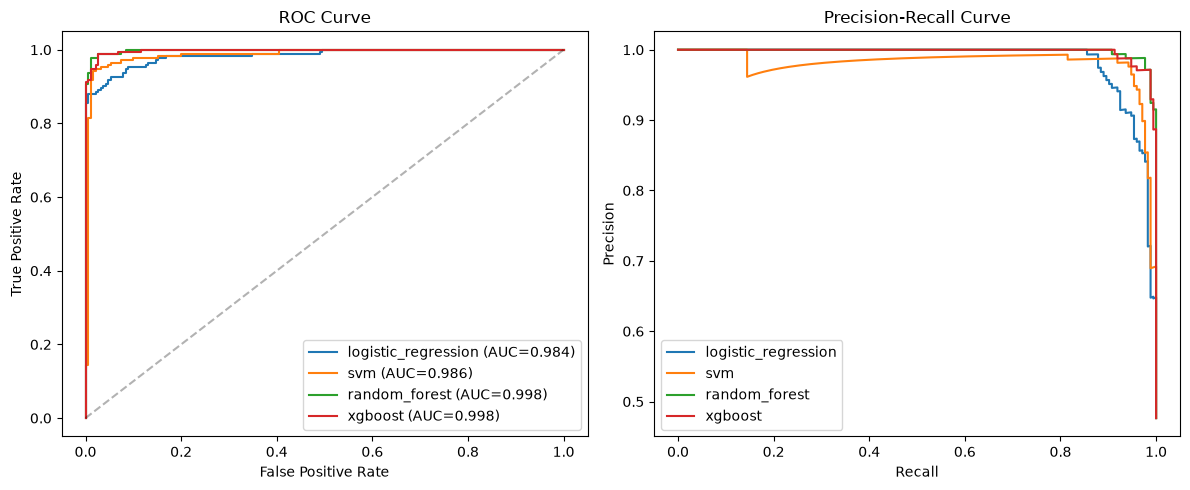

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, search in fitted_models.items():
    y_proba = search.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_proba):.3f})")

    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    axes[1].plot(rec, prec, label=name)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

### Breakdown by pair type

Each `type` group has a single ground-truth label, so "accuracy within the group" is exactly recall for the positive groups (hard/normal/code-changed positive) and exactly specificity for the negative groups (hard/normal negative). This shows whether a model's good overall F1 is coming from the easy cases or whether it actually holds up on the hard ones.

In [22]:
type_rows = []
for name, search in fitted_models.items():
    y_pred = search.predict(X_test)
    correct = pd.Series(y_pred == y_test.values, index=test_features.index)
    type_rows.append(correct.groupby(test_features["type"]).mean().rename(name))

type_breakdown = pd.concat(type_rows, axis=1)
type_breakdown["n_pairs"] = test_features["type"].value_counts()
display(type_breakdown)

/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,logistic_regression,svm,random_forest,xgboost,n_pairs
type,,,,,
code changed positive,0.750000,0.900000,1.000000,1.000000,20
hard negative,0.906667,0.973333,0.986667,0.986667,75
hard positive,0.946667,0.893333,0.920000,0.973333,75
heliport negative,0.975000,1.000000,0.975000,0.900000,40
heliport positive,1.000000,1.000000,1.000000,1.000000,3
normal negative,0.973333,0.986667,1.000000,1.000000,75
normal positive,0.946667,0.946667,1.000000,1.000000,75


### Error Analysis

Not just the error counts - looking at the actual mis-classified pairs to find patterns

#### False Positives and False Negatives

In [23]:
error_table = test_features[["id1", "id2", "type", "label"]].copy()
for name, search in fitted_models.items():
    error_table[f"pred_{name}"] = search.predict(X_test)

summary_rows = []
for name in fitted_models:
    pred = error_table[f"pred_{name}"]
    fp = ((pred == 1) & (error_table["label"] == 0)).sum()
    fn = ((pred == 0) & (error_table["label"] == 1)).sum()
    summary_rows.append({"model": name, "false_positives": fp, "false_negatives": fn})

display(pd.DataFrame(summary_rows).set_index("model"))

print("\nfalse negatives by type (which kind of positive gets missed):")
for name in fitted_models:
    pred = error_table[f"pred_{name}"]
    fn_mask = (pred == 0) & (error_table["label"] == 1)
    print(f"  {name}:")
    print(error_table.loc[fn_mask, "type"].value_counts().to_string())

print("\nfalse positives by type (which kind of negative gets flagged as a match):")
for name in fitted_models:
    pred = error_table[f"pred_{name}"]
    fp_mask = (pred == 1) & (error_table["label"] == 0)
    print(f"  {name}:")
    print(error_table.loc[fp_mask, "type"].value_counts().to_string())

/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,false_positives,false_negatives
model,,
logistic_regression,10,13
svm,3,14
random_forest,2,6
xgboost,5,2



false negatives by type (which kind of positive gets missed):
  logistic_regression:
type
code changed positive    5
hard positive            4
normal positive          4
  svm:
type
hard positive            8
normal positive          4
code changed positive    2
  random_forest:
type
hard positive    6
  xgboost:
type
hard positive    2

false positives by type (which kind of negative gets flagged as a match):
  logistic_regression:
type
hard negative        7
normal negative      2
heliport negative    1
  svm:
type
hard negative      2
normal negative    1
  random_forest:
type
hard negative        1
heliport negative    1
  xgboost:
type
heliport negative    4
hard negative        1


##### Inspect the pairs side by side

`show_pair_details` prints every column `df_wd` and `df_oa` have in common (`name`, `iata`, `icao`, `lat`, `lon`, `elevation`, `countryName`, `city`, `localCode`, `countryCode`) side by side for each pair - the raw data, not the derived similarity features - the same kind of view used in `create_gold_standard.ipynb` (`inspect_pairs`), rebuilt here since that helper lives in the other notebook. Defaults to the model with the best test F1 from the metrics table above; change `MODEL_TO_INSPECT` to look at a different one.

In [24]:
SHARED_COLS = [c for c in df_wd.columns if c in df_oa.columns and c != "id"]
print(f"shared columns: {SHARED_COLS}")


def show_pair_details(pairs_df, n=10):
    left = df_wd.set_index("id")[SHARED_COLS].add_suffix("_wd")
    right = df_oa.set_index("id")[SHARED_COLS].add_suffix("_oa")
    view = pairs_df[["id1", "id2", "type"]].join(left, on="id1").join(right, on="id2")
    for _, r in view.head(n).iterrows():
        print(f"({r['id1']} <-> {r['id2']})  type={r['type']}")
        for c in SHARED_COLS:
            print(f"  {c:12s} WD: {str(r[c + '_wd']):30s} OA: {r[c + '_oa']}")
        print()


MODEL_TO_INSPECT = results.index[0]  # best model by test F1 (dynamic, see the metrics table above)
pred = error_table[f"pred_{MODEL_TO_INSPECT}"]

print(f"=== {MODEL_TO_INSPECT}: false positives (predicted match, gold says no) ===\n")
show_pair_details(error_table[(pred == 1) & (error_table["label"] == 0)])

print(f"=== {MODEL_TO_INSPECT}: false negatives (predicted non-match, gold says yes) ===\n")
show_pair_details(error_table[(pred == 0) & (error_table["label"] == 1)])

shared columns: ['name', 'iata', 'icao', 'lat', 'lon', 'elevation', 'countryName', 'city', 'localCode', 'countryCode']
=== xgboost: false positives (predicted match, gold says no) ===

(wd_4082 <-> oa_49715)  type=hard negative
  name         WD: leaf cay airport               OA: staniel cay airport
  iata         WD: nan                            OA: TYM
  icao         WD: MYXD                           OA: MYES
  lat          WD: 24.14570498666                 OA: 24.1691
  lon          WD: -76.45860014154                OA: -76.439102
  elevation    WD: 2.0                            OA: 1.524
  countryName  WD: the bahamas                    OA: bahamas
  city         WD: the bahamas                    OA: staniel cay
  localCode    WD: nan                            OA: nan
  countryCode  WD: BS                             OA: BS

(wd_2385 <-> oa_33732)  type=heliport negative
  name         WD: foggia gino lisa airport       OA: alidaunia foggia heliport
  iata         WD: FOG 

##### Findings:

1. **Heliport/aerodrome pairs that sit too close together**: `wd_24154` (Waiheke Island Aerodrome) and `oa_51572` (Onetangi Heliport) are only 1.4 km apart but are two different facilities on the same island - different name, different ICAO (`NZKE` vs. `NZOW`). `distance_km` alone reads "1.4 km" as close enough to be the same airport, and that signal outweighs the dissimilar name/ICAO, producing a false positive. We need to give the model heliport information so it can learn that heliports need a tighter distance match than regular airports. OA has a `type` column, WD does not, so the flags use the OA `type` or the name (WD: name only); they are added in the before/after ablation below.


2. **Missing values default to 0.0**: by default, a comparator returns `0.0` when either side is missing the compared column - the same score a genuine mismatch would get. That conflates "we don't know" with "truly dissimilar." For example, `zhaosu airport`/`zhaosu tianma airport` has a missing OA `elevation`, which gets scored as if the elevations were completely different, even though the pair shares the token `"zhaosu"` and sits at a plausible distance - a case we'd otherwise expect to classify correctly. We add `NeutralOnMissingComparator` (neutral `0.5` instead of `0.0`) plus a `MissingFlagComparator` for the columns that are frequently missing (`city`, `countryName`, `countryCode`, `localCode`, `elevation`), added in the before/after ablation below.

#### Before/After: Missing-Value Handling & Heliport Flag

Sections 2-4 deliberately use a **baseline** feature set: plain comparators for `city`/`countryName`/`countryCode`/`localCode`/`elevation` (missing -> 0.0, no flag column) and no heliport features. Now that error analysis above has identified two gaps, we add them on top of that baseline to build an **after** feature set:

1. The `NeutralOnMissingComparator`/`MissingFlagComparator` pattern (missing values score as neutral 0.5 instead of a maximally-dissimilar 0.0, with a separate flag column) for `city`, `countryName`, `countryCode`, `localCode`, `elevation`.
2. Three heliport features: `is_heliport_wd`, `is_heliport_oa` and `heliport_mismatch` (exactly one of the two records is a heliport). The definition is the same as in the gold standard: OurAirports `type == "heliport"` or a name starting with `heli`; Wikidata has no `type` column, so only the name is used. We match `heli` at the start of a word, because a plain substring also hits names like Chelinda, Moheli or Richelieu.


We retrain the same four model architectures on this after feature set, then compare the single best model from Section 3/4 (`results`, the baseline) against the single best model trained here on the after features.


In [25]:
class NeutralOnMissingComparator(BaseComparator):
    """Wraps a comparator so a missing value on either side returns a neutral score
    instead of the wrapped comparator's default of 0.0 (= maximally dissimilar).
    This re-write the return values of comparators, which default is 0.0. 
    """

    def __init__(self, inner, column, neutral=0.5):
        super().__init__(name=f"NeutralOnMissing({inner.name})")
        self.inner = inner
        self.column = column
        self.neutral = neutral

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        if pd.isna(v1) or pd.isna(v2):
            return self.neutral
        return self.inner.compare(record1, record2)


class MissingFlagComparator(BaseComparator):
    """1.0 if either side is missing this column, else 0.0.
    It will create new columns (features), showing the features has missing value or not. 
    """

    def __init__(self, column):
        super().__init__(name=f"MissingFlagComparator({column})")
        self.column = column

    def compare(self, record1, record2):
        v1, v2 = record1.get(self.column), record2.get(self.column)
        return 1.0 if (pd.isna(v1) or pd.isna(v2)) else 0.0

In [26]:
import re

HELI_NAME = re.compile(r"\bheli")   # same definition as the gold standard


def has_heli_name(name):
    return isinstance(name, str) and HELI_NAME.search(name) is not None


def wd_is_heliport(record):          # Wikidata has no `type` column: name only
    return has_heli_name(record.get("name"))


def oa_is_heliport(record):          # OurAirports: type, or the name (also catches `closed` heliports)
    return record.get("type") == "heliport" or has_heli_name(record.get("name"))


class HeliportWDComparator(BaseComparator):
    def __init__(self):
        super().__init__(name="is_heliport_wd")

    def compare(self, record1, record2):      # record1 = Wikidata, record2 = OurAirports
        return float(wd_is_heliport(record1))


class HeliportOAComparator(BaseComparator):
    def __init__(self):
        super().__init__(name="is_heliport_oa")

    def compare(self, record1, record2):
        return float(oa_is_heliport(record2))


class HeliportMismatchComparator(BaseComparator):
    """1.0 if exactly one of the two records is a heliport (airport vs. heliport)."""

    def __init__(self):
        super().__init__(name="heliport_mismatch")

    def compare(self, record1, record2):
        return float(wd_is_heliport(record1) != oa_is_heliport(record2))


#### Why NeutralOnMissingComparator (return 0.5 instead of 0.0 on missing):

By default, a comparator returns 0.0 when either side's value is missing — identical to a genuine "completely dissimilar" score. This causes two problems: it conflates "no data" with "truly dissimilar," and when fed through StandardScaler (for Logistic Regression/SVM), these artificial 0.0s skew the column's mean/std for every row, not just the missing ones. Replacing it with a neutral 0.5 avoids both issues.

#### Why that alone isn't enough — need MissingFlagComparator too:

Setting missing values to 0.5 just moves the problem: now a missing pair and a pair that genuinely scores 0.5 similarity look identical to the model — one number can't represent two different situations. Whatever constant you pick to represent "unknown," it will always collide with real cases that happen to score the same value.

The fix is a separate flag column (1 if missing, 0 otherwise). It doesn't force any particular correction — the model learns from the training data whether missing-ness correlates with matches being more or less likely (it could go either way, or not matter at all, in which case its weight just stays near zero).

In [27]:
MISSING_VALUE_COLUMNS = {
    "city": city_comparators,
    "countryName": countryname_comparators,
    "countryCode": countrycode_comparators,
    "localCode": localcode_comparators,
    "elevation": elevation_comparators,
}


def add_missing_handling(raw_comparators, column):
    """Wrap each raw comparator with NeutralOnMissingComparator (missing -> neutral 0.5)
    and append a MissingFlagComparator for that column."""
    wrapped = [NeutralOnMissingComparator(c, column=column) for c in raw_comparators]
    wrapped.append(MissingFlagComparator(column=column))
    return wrapped


after_comparators = list(name_comparators)
for column, raw in MISSING_VALUE_COLUMNS.items():
    after_comparators += add_missing_handling(raw, column)
after_comparators += geo_comparators + [HeliportWDComparator(), HeliportOAComparator(), HeliportMismatchComparator()]

print(f"baseline (before) feature comparators: {len(comparators)}")
print(f"after             feature comparators: {len(after_comparators)}")


baseline (before) feature comparators: 26
after             feature comparators: 34


In [28]:
after_extractor = FeatureExtractor(after_comparators)
AFTER_FEATURE_COLS = after_extractor.get_feature_names()

after_train_val_features = after_extractor.create_features(
    df_wd, df_oa, train_val_r[["id1", "id2"]], id_column="id", labels=train_val_r["label"]
)
after_test_features = after_extractor.create_features(
    df_wd, df_oa, test_r[["id1", "id2"]], id_column="id", labels=test_r["label"]
)

X_after_train_val = after_train_val_features[AFTER_FEATURE_COLS]
y_after_train_val = after_train_val_features["label"]
X_after_test = after_test_features[AFTER_FEATURE_COLS]
y_after_test = after_test_features["label"]

print(f"after train_val feature matrix: {X_after_train_val.shape}")
print(f"after test feature matrix:      {X_after_test.shape}")


after train_val feature matrix: (847, 34)
after test feature matrix:      (363, 34)


Train the same four model architectures (same pipelines, hyperparameter grids, and CV folds as Section 3) on the after feature set. The grids are re-declared here -- rather than reused from Section 3's cells, which only kept them inline inside each `fit_model` call -- so this ablation can run as a self-contained rerun.


In [29]:
MODEL_SPECS = {
    "logistic_regression": (
        Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "svm": (
        Pipeline([("scaler", StandardScaler()), ("clf", SVC(probability=True, random_state=SEED))]),
        {"clf__C": [0.1, 1.0, 10.0], "clf__kernel": ["rbf", "linear"]},
    ),
    "random_forest": (
        Pipeline([("clf", RandomForestClassifier(random_state=SEED))]),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 10, 20]},
    ),
    "xgboost": (
        Pipeline([("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1))]),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 6], "clf__learning_rate": [0.05, 0.1]},
    ),
}

after_fitted_models = {}
for name, (pipeline, param_grid) in MODEL_SPECS.items():
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1", n_jobs=1)
    search.fit(X_after_train_val, y_after_train_val)
    after_fitted_models[name] = search
    print(f"{name:<22} best CV F1 = {search.best_score_:.3f}  best params = {search.best_params_}")


logistic_regression    best CV F1 = 0.943  best params = {'clf__C': 10.0}


/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.ven

svm                    best CV F1 = 0.957  best params = {'clf__C': 10.0, 'clf__kernel': 'rbf'}
random_forest          best CV F1 = 0.981  best params = {'clf__max_depth': None, 'clf__n_estimators': 300}
xgboost                best CV F1 = 0.983  best params = {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 100}


In [30]:
after_rows = []
for name, search in after_fitted_models.items():
    y_pred = search.predict(X_after_test)
    y_proba = search.predict_proba(X_after_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_after_test, y_pred).ravel()
    after_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_after_test, y_pred),
        "precision": precision_score(y_after_test, y_pred),
        "recall": recall_score(y_after_test, y_pred),
        "f1": f1_score(y_after_test, y_pred),
        "roc_auc": roc_auc_score(y_after_test, y_proba),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    })

after_results = pd.DataFrame(after_rows).set_index("model").sort_values("f1", ascending=False)
display(after_results)

best_after_name = after_results.index[0]
print(f"\nbest after model: {best_after_name}")
display(after_results.loc[[best_after_name]])


/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/huanglinchun/dev/studies/uni-mannheim/Web-Data-Integration/Web-Data-Integration-Project/.ven

,accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
model,,,,,,,,,
random_forest,0.988981,0.994152,0.982659,0.988372,0.999133,170,1,3,189
xgboost,0.980716,0.982558,0.976879,0.979710,0.998874,169,3,4,187
svm,0.966942,0.970760,0.959538,0.965116,0.992303,166,5,7,185
logistic_regression,0.953168,0.943182,0.959538,0.951289,0.994524,166,10,7,180



best after model: random_forest


,accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
model,,,,,,,,,
random_forest,0.988981,0.994152,0.982659,0.988372,0.999133,170,1,3,189


##### Best Model Comparison: Before vs. After

Compares the single best baseline model (Section 3/4's `results`) against the single best model trained here on the after features -- these can be different architectures, since the point is "what's the best model I'd ship before this feature work" vs "...after", not matching architectures one-to-one.


In [31]:
best_before_name = results.index[0]

METRIC_COLS = ["accuracy", "precision", "recall", "f1", "roc_auc", "tp", "fp", "fn", "tn"]
best_comparison = pd.DataFrame({
    "before": results.loc[best_before_name, METRIC_COLS],
    "after": after_results.loc[best_after_name, METRIC_COLS],
})
best_comparison["delta"] = best_comparison["after"] - best_comparison["before"]

print(f"before: {best_before_name}")
print(f"after:  {best_after_name}")
display(best_comparison)


before: xgboost
after:  random_forest


,before,after,delta
accuracy,0.980716,0.988981,0.008264
precision,0.971591,0.994152,0.022561
recall,0.988439,0.982659,-0.005780
f1,0.979943,0.988372,0.008429
roc_auc,0.997597,0.999133,0.001536
tp,171.000000,170.000000,-1.000000
fp,5.000000,1.000000,-4.000000
fn,2.000000,3.000000,1.000000
tn,185.000000,189.000000,4.000000


Since the model after adding new features performs slightly better than the original model, it is chosen as the final model.


## Feature Importance

Feature importance for the model actually used to score candidates in the Apply step below - the best model from the before/after ablation's `after_results` (Section 5), since that's the one we decided to ship. Tree models (Random Forest, XGBoost) expose `feature_importances_` (mean decrease in impurity); Logistic Regression and a linear-kernel SVM expose `coef_` (on the standardized feature scale, so magnitudes are directly comparable within that model). If the best model turns out to be an SVM with a non-linear kernel, neither is available.


distance_km                                                                                          0.251996
NeutralOnMissing(NumericComparator(elevation, absolute_difference, list_strategy=None))              0.092081
NeutralOnMissing(NumericComparator(elevation, relative_difference, list_strategy=None))              0.063335
MongeElkanComparator(name)                                                                           0.062524
ContainmentComparator(name)                                                                          0.055152
PhoneticOverlapComparator(name, soundex)                                                             0.045334
ExtendedJaccardComparator(name)                                                                      0.045250
StringComparator(name, overlap, tokenization=word, list_strategy=None)                               0.038893
NeutralOnMissing(ExactMatchComparator(localCode))                                                    0.037630
StringComp

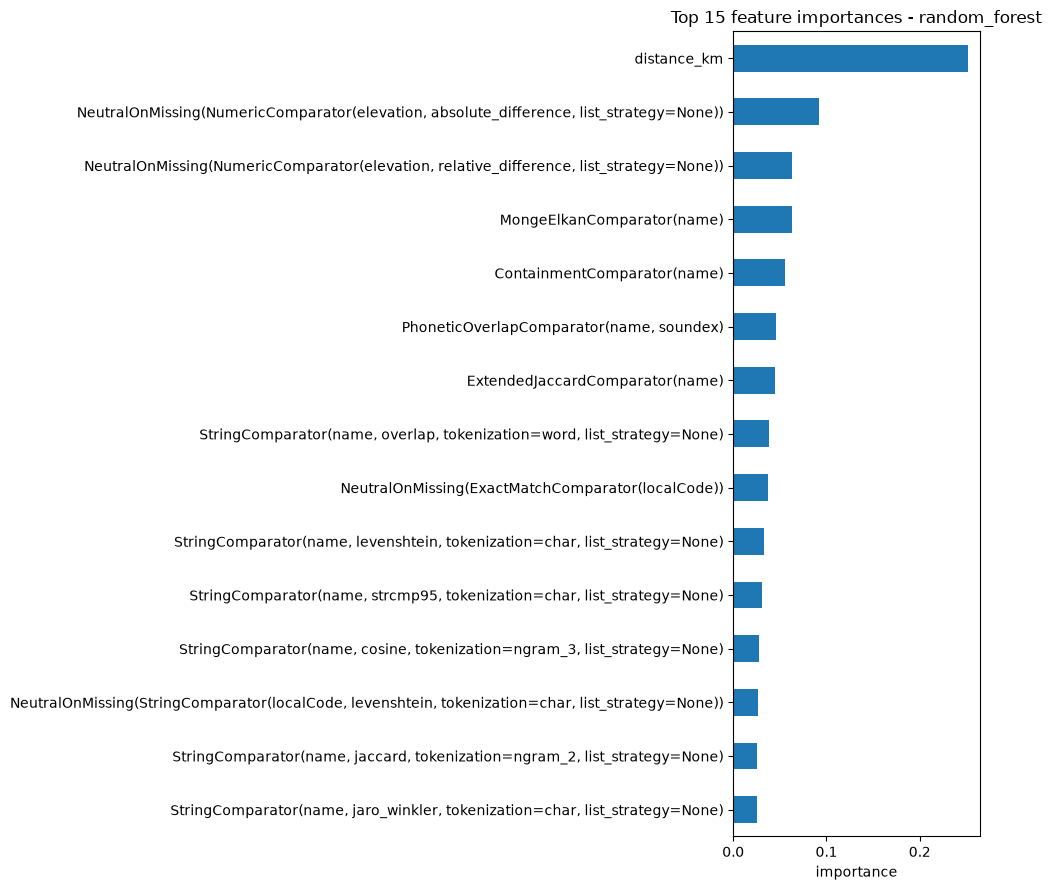

In [32]:
BEST_MODEL_NAME = best_after_name
best_model = after_fitted_models[BEST_MODEL_NAME]
clf = best_model.best_estimator_.named_steps["clf"]

if hasattr(clf, "feature_importances_"):
    importances = pd.Series(clf.feature_importances_, index=AFTER_FEATURE_COLS, name="importance")
elif hasattr(clf, "coef_"):
    importances = pd.Series(clf.coef_[0], index=AFTER_FEATURE_COLS, name="coefficient")
else:
    raise ValueError(
        f"{type(clf).__name__} exposes neither feature_importances_ nor coef_ "
        f"(e.g. an SVM with a non-linear kernel) - feature importance isn't available for this model"
    )

importances = importances.reindex(importances.abs().sort_values(ascending=False).index)
display(importances.head(15))

fig, ax = plt.subplots(figsize=(10, 9))
importances.head(15).iloc[::-1].plot.barh(ax=ax)
ax.set_xlabel(importances.name)
ax.set_title(f"Top 15 feature importances - {BEST_MODEL_NAME}")
plt.tight_layout()
plt.show()


## 7. Apply the Matcher

Block the full Wikidata x OurAirports datasets and score every candidate pair with the best-performing model. Conflicting candidates (the same record matched more than once) are not resolved into a one-to-one set here - see the Cluster Analysis section below, which tags and saves them instead. First step: blocking, reusing the exact Rule A (`countryCode` + distinguishing `name` token) and Rule B (H3 geographic grid) from `create_gold_standard.ipynb`, so the candidate pool the matcher sees is built the same way the gold standard's negatives were.


### Blocking

Three blocking rules, concatenated:
- **Rule A**: `countryCode` + distinguishing `name` token.
- **Rule B**: geographic grid (H3).
- **Rule C**: `countryCode` + `city` token.

#### Rule A

`TokenBlocker` on `name`, with `countryCode` prepended to each token (so a pair is a candidate only if the two records share a distinguishing token **and** have the same country). Tokens that would each create more than `MAX_PAIRS_PER_TOKEN` candidate pairs are excluded first (derived from the data, not hand-picked) - identical method to `create_gold_standard.ipynb`.

In [33]:
from collections import Counter

from PyDI.entitymatching import TokenBlocker

MAX_PAIRS_PER_TOKEN = 2000  # trade-off between block size and recall; tune with the debug CSV


def name_tokens(name):
    if not isinstance(name, str):
        return set()
    return {t for t in name.split() if len(t) >= 2}


doc_freq_wd = Counter(t for n in df_wd["name"] for t in name_tokens(n))
doc_freq_oa = Counter(t for n in df_oa["name"] for t in name_tokens(n))

COMMON_TOKENS = {
    t for t, c in doc_freq_wd.items()
    if c * doc_freq_oa.get(t, 0) > MAX_PAIRS_PER_TOKEN
}
print(f"Excluding {len(COMMON_TOKENS)} tokens that would each create more than "
      f"{MAX_PAIRS_PER_TOKEN} candidate pairs")


# The tokenizer only sees one column, so country and name are packed into one string.
def add_name_with_country(d):
    d = d.copy()
    d["name_with_country"] = d["countryCode"].fillna("") + "|" + d["name"].fillna("")
    return d


wd_blk = add_name_with_country(df_wd)
oa_blk = add_name_with_country(df_oa)


def country_scoped_tokenizer(text):
    if not isinstance(text, str) or "|" not in text:
        return []
    country, name = text.split("|", 1)
    if not country:          # Rule A needs a country code
        return []
    return [f"{country}_{t}" for t in name.split()
            if len(t) >= 2 and t not in COMMON_TOKENS]


blocker_token = TokenBlocker(
    df_left=wd_blk,
    df_right=oa_blk,
    column="name_with_country",
    id_column="id",
    tokenizer=country_scoped_tokenizer,
)

candidates_token = blocker_token.materialize()
print(f"Rule A candidate pairs: {len(candidates_token):,} "
      f"(estimated before materializing: {blocker_token.estimate_pairs():,})")

Excluding 131 tokens that would each create more than 2000 candidate pairs
Rule A candidate pairs: 198,724 (estimated before materializing: 206,951)


#### Rule B

Map each record to an H3 hexagonal cell (resolution `RESOLUTION`) and `TokenBlocker` the cell id plus its 6 neighbors (7 tokens per record), so two records in the same or adjacent cells always share a token. No `countryCode` requirement, and no `countryCode` in the token. Same method as in `create_gold_standard.ipynb`, but with resolution 7 instead of 9: the same airport often has coordinates several kilometres apart in the two sources, and at resolution 9 the 7 cells cover only about 0.5 km. This is also the resolution used for OurAirports x Kaggle.


In [34]:
import h3

RESOLUTION = 7   # was 9: the same airport often has coordinates several km apart in the two sources

def geo_h3_tokens(row):
    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        return []
    center = h3.latlng_to_cell(row["lat"], row["lon"], RESOLUTION)
    return list(h3.grid_disk(center, 1))


wd_geo = df_wd.copy()
oa_geo = df_oa.copy()

wd_geo["geo_grid_tokens"] = wd_geo.apply(geo_h3_tokens, axis=1)
oa_geo["geo_grid_tokens"] = oa_geo.apply(geo_h3_tokens, axis=1)

# one lookup for both sources (ids are prefixed, so they cannot collide)
grid_token_lookup = {
    **wd_geo.set_index("id")["geo_grid_tokens"].to_dict(),
    **oa_geo.set_index("id")["geo_grid_tokens"].to_dict(),
}


def grid_tokenizer(record_id):
    return grid_token_lookup.get(record_id, [])


# TokenBlocker only sees one column, so the id itself is the "text" to tokenize
wd_geo["id_as_text"] = wd_geo["id"]
oa_geo["id_as_text"] = oa_geo["id"]

blocker_geo = TokenBlocker(
    df_left=wd_geo,
    df_right=oa_geo,
    column="id_as_text",
    id_column="id",
    tokenizer=grid_tokenizer,
    min_token_len=1,
)

candidates_geo = blocker_geo.materialize()
print(f"Rule B candidate pairs: {len(candidates_geo):,}")

Rule B candidate pairs: 41,107


#### Rule C

`countryCode` + `city` token, the same rule as for OurAirports x Kaggle. It catches true matches whose names are very different and whose coordinates are too far apart for Rule B (e.g. a hospital heliport and an airport that share only the city). City tokens that would create more than `MAX_PAIRS_PER_CITY_TOKEN` pairs are excluded, in the same way as for Rule A.


In [35]:
MAX_PAIRS_PER_CITY_TOKEN = 500


def city_tokens(text):
    if not isinstance(text, str):
        return set()
    return {t for t in text.split() if len(t) >= 3}


city_freq_wd = Counter((c, t) for c, n in zip(df_wd["countryCode"], df_wd["city"]) for t in city_tokens(n))
city_freq_oa = Counter((c, t) for c, n in zip(df_oa["countryCode"], df_oa["city"]) for t in city_tokens(n))
COMMON_CITY_TOKENS = {
    k for k, c in city_freq_wd.items()
    if c * city_freq_oa.get(k, 0) > MAX_PAIRS_PER_CITY_TOKEN
}
print(f"Excluding {len(COMMON_CITY_TOKENS)} (country, city token) keys")


def add_city_with_country(d):
    d = d.copy()
    d["city_with_country"] = d["countryCode"].fillna("") + "|" + d["city"].fillna("")
    return d


def country_city_tokenizer(text):
    if not isinstance(text, str) or "|" not in text:
        return []
    country, city = text.split("|", 1)
    if not country:
        return []
    return [f"{country}_{t}" for t in city_tokens(city) if (country, t) not in COMMON_CITY_TOKENS]


blocker_city = TokenBlocker(
    df_left=add_city_with_country(df_wd),
    df_right=add_city_with_country(df_oa),
    column="city_with_country",
    id_column="id",
    tokenizer=country_city_tokenizer,
)

candidates_city = blocker_city.materialize()
print(f"Rule C candidate pairs: {len(candidates_city):,}")


Excluding 101 (country, city token) keys
Rule C candidate pairs: 86,716


#### Concatenate and Deduplicate

In [36]:
candidates = pd.concat(
    [candidates_geo[["id1", "id2"]], candidates_token[["id1", "id2"]], candidates_city[["id1", "id2"]]],
    axis=0,
)
candidates = candidates.drop_duplicates(subset=["id1", "id2"]).reset_index(drop=True)

print(f"All candidate pairs after deduplication: {len(candidates):,}")


All candidate pairs after deduplication: 296,497


#### Ground-Truth Positives for Blocking Recall

The gold standard's 577 sampled positives are a biased, small sample (half of them deliberately picked as the *hardest* cases). To get a recall estimate with real statistical power and that reflects what blocking will actually face at full scale, build the ground-truth positives directly from the full data instead, the same two ways `create_gold_standard.ipynb` found positives in the first place:

1. **ICAO merge**: valid ICAO present and equal on both sides.
2. **ICAO differs, IATA matches**: valid IATA present and equal on both sides, ICAO differs, within 50 km (same rule as the code-changed positives).

The two are disjoint by construction (one requires equal ICAO, the other requires differing ICAO) and are combined by union.

In [37]:
valid_icao = r"^[A-Z0-9]{4}$"
valid_iata = r"^[A-Z]{3}$"

# 1. ICAO merge
wd_icao = df_wd[df_wd["icao"].astype(str).str.match(valid_icao, na=False)]
oa_icao = df_oa[df_oa["icao"].astype(str).str.match(valid_icao, na=False)]
icao_pairs = pd.merge(wd_icao, oa_icao, on="icao", how="inner", suffixes=("_wd", "_oa"))
print(f"dataset 1 (ICAO merge): {len(icao_pairs):,} pairs")

# 2. ICAO differs, IATA matches, within 50 km
wd_iata = df_wd[df_wd["iata"].astype(str).str.match(valid_iata, na=False)]
oa_iata = df_oa[df_oa["iata"].astype(str).str.match(valid_iata, na=False)]
iata_pairs = pd.merge(wd_iata, oa_iata, on="iata", how="inner", suffixes=("_wd", "_oa"))

iata_pairs["dist_km"] = [
    haversine_km(a, b, c, d)
    for a, b, c, d in zip(iata_pairs["lat_wd"], iata_pairs["lon_wd"],
                          iata_pairs["lat_oa"], iata_pairs["lon_oa"])
]
icao_differs = iata_pairs["icao_wd"] != iata_pairs["icao_oa"]
code_changed_pairs = iata_pairs[icao_differs & (iata_pairs["dist_km"].fillna(999) <= 50)]
print(f"dataset 2 (ICAO differs, IATA matches, <=50km): {len(code_changed_pairs):,} pairs")

# combine
ground_truth_positives = (
    set(icao_pairs[["id_wd", "id_oa"]].itertuples(index=False, name=None))
    | set(code_changed_pairs[["id_wd", "id_oa"]].itertuples(index=False, name=None))
)
print(f"combined ground-truth positives: {len(ground_truth_positives):,} pairs")

dataset 1 (ICAO merge): 7,758 pairs
dataset 2 (ICAO differs, IATA matches, <=50km): 724 pairs
combined ground-truth positives: 8,482 pairs


### Blocking Key Validation: Recall & Reduction Ratio

Measure the blocking step (Rules A, B and C, deduplicated) against `ground_truth_positives` (built above):

- **Recall (Pair Completeness)**: for each ground-truth positive pair, check whether that exact `(id1, id2)` pair ended up in `candidates`. Recall is the fraction that did.
- **Reduction Ratio** = `1 - (candidate pairs) / (|WD| x |OA|)`.

Target from the Methods above: recall > 97%.

In [38]:
found_pairs = set(candidates[["id1", "id2"]].itertuples(index=False, name=None))
hits = sum(1 for p in ground_truth_positives if p in found_pairs)
recall_pc = hits / len(ground_truth_positives)

total_possible_pairs = len(df_wd) * len(df_oa)
reduction_ratio = 1 - len(candidates) / total_possible_pairs

print(f"candidate pairs: {len(candidates):,}")
print(f"recall (pair completeness): {recall_pc:.4f}  ({hits:,}/{len(ground_truth_positives):,})")
print(f"reduction ratio: {reduction_ratio:.6f}")
print(f"recall > 97%: {recall_pc > 0.97}")

candidate pairs: 296,497
recall (pair completeness): 0.9943  (8,434/8,482)
reduction ratio: 0.999862
recall > 97%: True


### Extract Features for All Candidates

Reuse the same `after_extractor` (the after-ablation feature set from Section 5 - the baseline comparators plus missing-value handling and the heliport features, since that's the feature set the model we're shipping was trained on) on the full blocked `candidates` set - no labels this time, since these are unlabeled real-world pairs, not gold-standard pairs. Same consistency reasoning as before: the exact feature-computation code used for training must be used here, or the model is scoring something different from what it learned on.


In [39]:
candidate_features = after_extractor.create_features(
    df_wd, df_oa, candidates[["id1", "id2"]], id_column="id"
)

print(f"candidate feature matrix: {candidate_features.shape}")
display(candidate_features.head(3))


candidate feature matrix: (296497, 36)


,id1,id2,"StringComparator(name, levenshtein, tokenization=char, list_strategy=None)","StringComparator(name, jaro, tokenization=char, list_strategy=None)","StringComparator(name, jaro_winkler, tokenization=char, list_strategy=None)","StringComparator(name, strcmp95, tokenization=char, list_strategy=None)","StringComparator(name, jaccard, tokenization=word, list_strategy=None)","StringComparator(name, sorensen_dice, tokenization=word, list_strategy=None)","StringComparator(name, overlap, tokenization=word, list_strategy=None)","StringComparator(name, cosine, tokenization=word, list_strategy=None)",...,NeutralOnMissing(ExactMatchComparator(localCode)),MissingFlagComparator(localCode),"NeutralOnMissing(NumericComparator(elevation, absolute_difference, list_strategy=None))","NeutralOnMissing(NumericComparator(elevation, relative_difference, list_strategy=None))",MissingFlagComparator(elevation),distance_km,coordinate_missing,is_heliport_wd,is_heliport_oa,heliport_mismatch
0,wd_1,oa_19599,0.8,0.85,0.88,0.88,0.666667,0.8,1.0,0.816497,...,0.5,1.0,0.996488,0.991833,0.0,0.070360,0.0,0.0,0.0,0.0
1,wd_2,oa_85742,1.0,1.00,1.00,1.00,1.000000,1.0,1.0,1.000000,...,0.5,1.0,0.500000,0.500000,1.0,0.000088,0.0,0.0,0.0,0.0
2,wd_3,oa_85933,1.0,1.00,1.00,1.00,1.000000,1.0,1.0,1.000000,...,0.5,1.0,0.500000,0.500000,1.0,0.000054,0.0,0.0,0.0,0.0


### Score with the Best Model

Pick the model with the best test F1 from the `after_results` metrics table (the before/after ablation in Section 5), rather than hard-coding a name, since that table is the thing that actually decides "best" among the models trained on the feature set we're shipping. Score every candidate with `predict_proba`, then keep only pairs at or above the threshold chosen by cross-validation, shown below.


In [40]:
BEST_MODEL_NAME = after_results.index[0]
best_model = after_fitted_models[BEST_MODEL_NAME]
print(f"applying best model: {BEST_MODEL_NAME}")

X_candidates = candidate_features[AFTER_FEATURE_COLS]
candidate_features["score"] = best_model.predict_proba(X_candidates)[:, 1]

applying best model: random_forest


In [41]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Choose MATCH_THRESHOLD with the same 5 folds as the tuning. Only train_val is used; test stays untouched.
# Out-of-fold probabilities: each train_val pair is scored by a model that did not see its fold.
oof_proba = cross_val_predict(
    best_model.best_estimator_, X_after_train_val, y_after_train_val,
    cv=cv, method="predict_proba",
)[:, 1]

oa_type = df_oa.set_index("id")["type"]
rows = []
for t in np.arange(0.30, 0.96, 0.05):
    pred = oof_proba >= t
    matched = candidate_features[candidate_features["score"] >= t]
    rows.append({
        "threshold": round(t, 2),
        # gold-standard metrics (cross-validation)
        "cv_precision": precision_score(y_after_train_val, pred),
        "cv_recall": recall_score(y_after_train_val, pred),
        "cv_f1": f1_score(y_after_train_val, pred),
        # checks on all candidate pairs (the gold standard has no such pairs)
        "candidate_matches": len(matched),
        "records_matched_more_than_once": int(matched["id1"].duplicated().sum()
                                               + matched["id2"].duplicated().sum()),
        "heliport_mismatch_matches": int(matched["heliport_mismatch"].sum()),
    })
threshold_table = pd.DataFrame(rows)
display(threshold_table)

# among thresholds within F1_TOLERANCE of the best CV F1, take the one with the fewest conflicts
F1_TOLERANCE = 0.01
ok = threshold_table[threshold_table["cv_f1"] >= threshold_table["cv_f1"].max() - F1_TOLERANCE]
MATCH_THRESHOLD = float(ok.sort_values(["records_matched_more_than_once", "heliport_mismatch_matches"])
                          .iloc[0]["threshold"])
print(f"chosen MATCH_THRESHOLD = {MATCH_THRESHOLD}")


,threshold,cv_precision,cv_recall,cv_f1,candidate_matches,records_matched_more_than_once,heliport_mismatch_matches
0,0.30,0.957041,0.992574,0.974484,40167,26846,789
1,0.35,0.959233,0.990099,0.974421,32987,14597,563
2,0.40,0.973171,0.987624,0.980344,30372,10518,389
3,0.45,0.975550,0.987624,0.981550,28877,8274,241
4,0.50,0.980247,0.982673,0.981459,27599,6399,129
5,0.55,0.987437,0.972772,0.980050,26779,5249,87
6,0.60,0.992386,0.967822,0.979950,26142,4356,63
7,0.65,0.992308,0.957921,0.974811,25461,3444,44
8,0.70,0.994792,0.945545,0.969543,24694,2561,25
9,0.75,0.994695,0.928218,0.960307,23971,1876,12


chosen MATCH_THRESHOLD = 0.65


In [42]:
# Pairs with a missing coordinate are never accepted automatically.
# The distance feature (the most important one) is unknown for them and falls back to a constant (2.0 km),
# and the gold standard has only 1 such pair, so the model cannot learn to score them.
# A threshold above 1 can never be reached, so these pairs are excluded.
MISSING_COORD_THRESHOLD = 1.01

missing = candidate_features["coordinate_missing"] == 1
accept = np.where(missing,
                  candidate_features["score"] >= MISSING_COORD_THRESHOLD,
                  candidate_features["score"] >= MATCH_THRESHOLD)
above_threshold = candidate_features[accept][["id1", "id2", "score"]]

print(f"{int(missing.sum()):,} candidate pairs have a missing coordinate; "
      f"{int((missing & (candidate_features['score'] >= MATCH_THRESHOLD)).sum()):,} would pass {MATCH_THRESHOLD}, "
      f"{int((missing & (candidate_features['score'] >= MISSING_COORD_THRESHOLD)).sum()):,} are accepted")

515 candidate pairs have a missing coordinate; 231 would pass 0.65, 0 are accepted


In [43]:
# Test split, per gold-standard group: share correct (recall for positive groups, specificity for negative groups)
def by_type_table(threshold):
    y_proba = best_model.predict_proba(X_after_test)[:, 1]
    correct = pd.Series((y_proba >= threshold) == y_after_test.to_numpy())
    return (correct.groupby(test_r["type"].to_numpy())
                   .agg(share_correct="mean", n_pairs="size").round(3))

display(pd.concat({"threshold 0.5": by_type_table(0.5),
                   f"threshold {MATCH_THRESHOLD}": by_type_table(MATCH_THRESHOLD)}, axis=1))


threshold 0.5         threshold 0.65        
                      share_correct n_pairs  share_correct n_pairs
code changed positive         1.000      20          0.950      20
hard negative                 0.987      75          0.987      75
hard positive                 0.960      75          0.933      75
heliport negative             1.000      40          1.000      40
heliport positive             1.000       3          1.000       3
normal negative               1.000      75          1.000      75
normal positive               1.000      75          1.000      75

## Cluster Analysis

Group the above-threshold pairs into connected components (plain union-find, not PyDI's `ConnectedComponentClusterer` - that one outputs *all pairwise combinations* within a cluster, including, e.g., an OA-OA pair inside a 3-node cluster, which has no meaning in our WD-vs-OA setup). Each pair keeps its own `score`; `cluster` just tags which component it belongs to, so a cluster with more than 2 members (a conflict - the same WD or OA record matched to more than one record on the other side) is visible directly in the saved output. The conflicts are resolved by one-to-one matching below, after the clusters have been inspected.


In [44]:
def find_clusters(pairs_df):
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            x = parent[x]
        return x

    def union(x, y):
        rx, ry = find(x), find(y)
        if rx != ry:
            parent[rx] = ry

    for _, row in pairs_df.iterrows():
        union(row["id1"], row["id2"])

    groups = {}
    for node in parent:
        groups.setdefault(find(node), set()).add(node)
    return list(groups.values())


clusters = find_clusters(above_threshold)
cluster_sizes = pd.Series([len(c) for c in clusters])

print(f"{len(clusters):,} connected components from {len(above_threshold):,} above-threshold pairs")
print("\ncluster size frequency:")
print(cluster_sizes.value_counts().sort_index())

id_to_cluster = {node: i for i, cluster in enumerate(clusters) for node in cluster}

final_correspondences = above_threshold.copy()
final_correspondences["cluster"] = final_correspondences["id1"].map(id_to_cluster)
final_correspondences = final_correspondences.rename(columns={"id1": "id_1", "id2": "id_2"})
final_correspondences = final_correspondences[["id_1", "id_2", "score", "cluster"]]

print(f"\n{len(final_correspondences):,} correspondences, tagged with their cluster id")
display(final_correspondences.head(3))


22,444 connected components from 25,230 above-threshold pairs

cluster size frequency:
2     20834
3      1083
4       368
5        78
6        47
7        13
8        12
9         3
12        2
13        1
15        2
19        1
Name: count, dtype: int64

25,230 correspondences, tagged with their cluster id


,id_1,id_2,score,cluster
0,wd_1,oa_19599,0.973333,0
1,wd_2,oa_85742,0.983333,1
2,wd_3,oa_85933,0.963333,2


In [45]:
import numpy as np

multi_clusters = [c for c in clusters if len(c) > 2]
print(f"{len(multi_clusters):,} / {len(clusters):,} clusters have more than 2 members")

coords = pd.concat([
    df_wd.set_index("id")[["lat", "lon"]],
    df_oa.set_index("id")[["lat", "lon"]],
])


def cluster_max_distance_km(node_ids):
    pts = coords.loc[coords.index.intersection(node_ids)].dropna()[["lat", "lon"]].values
    if len(pts) < 2:
        return np.nan
    max_dist = 0.0
    for i in range(len(pts)):
        for j in range(i + 1, len(pts)):
            max_dist = max(max_dist, haversine_km(pts[i][0], pts[i][1], pts[j][0], pts[j][1]))
    return max_dist


cluster_max_dist = pd.Series([cluster_max_distance_km(c) for c in multi_clusters])

print("\nmax pairwise distance within each >2-member cluster:")
display(cluster_max_dist.describe())

distance_buckets = pd.cut(
    cluster_max_dist,
    bins=[-0.001, 5, 50, float("inf")],
    labels=["tight (<=5km)", "mid (5-50km)", "far (>50km)"],
)
print("\nbucketed:")
print(distance_buckets.value_counts().sort_index())


1,610 / 22,444 clusters have more than 2 members

max pairwise distance within each >2-member cluster:


count    1610.000000
mean       40.307237
std       304.246551
min         0.000077
25%         1.105811
50%         2.091416
75%         3.134497
max      6517.137187
dtype: float64


bucketed:
tight (<=5km)    1359
mid (5-50km)      191
far (>50km)        60
Name: count, dtype: int64


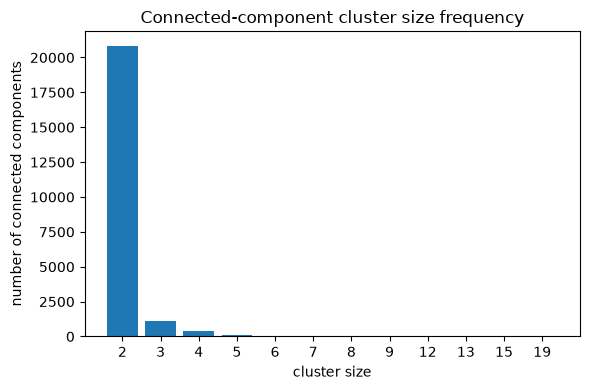

In [46]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cluster_sizes.value_counts().sort_index().index.astype(str),
       cluster_sizes.value_counts().sort_index().values)
ax.set_xlabel("cluster size")
ax.set_ylabel("number of connected components")
ax.set_title("Connected-component cluster size frequency")
plt.tight_layout()
plt.show()


1,610 of the 22,444 clusters have more than 2 members - i.e. the same WD or OA record matched to more than one record on the other side. Bucketing each cluster's maximum pairwise distance between its members shows these conflicts are not one uniform problem:

- **tight (<=5km), 1,359 clusters (84%)**: includes genuine duplicate records *within* one source for the same real airport - e.g. OA carrying both `sturgis municipal airport` and `old sturgis airport`, or a current/duplicate-flagged pair like `oa_17981` literally named `"duplicateyeg"` next to `edmonton international airport`. but a sample of the clusters with 3-4 records (below) shows that most extra links are wrong.
- **far (>50km), 60 clusters (4%)**: almost entirely matcher false positives, usually a shared generic name token linking genuinely different airports 
    -  four distinct Chongqing-area airports chained together through `"chongqing"` + `"airport"`
    - `wd_5192` (`curtiss southwest field`, all core fields including lat/lon missing) matched to 24 unrelated `"southwest ___ airport"` OA records across the US purely because `distance_km` falls back to a constant when coordinates are missing (pairs with a missing coordinate are now never accepted).
- **mid (5-50km), 191 clusters (12%)**: ambiguous - a mix of the noisy-coordinate same-airport pattern from error analysis and genuine false positives.

(The examples were taken from an earlier run with the threshold 0.5 and the narrower blocking; the counts are from the current run.)

## Dive deeply into clusters
Inspect the airport `name`s for all clusters with size > 2.

In [47]:
nm = {**df_wd.set_index("id")["name"].to_dict(), **df_oa.set_index("id")["name"].to_dict()}
by_size = {}
for c in clusters:
    by_size.setdefault(len(c), []).append(sorted(c))

for size in range(3, 20):
    for ids in by_size.get(size, [])[:3]:
        print(size, [nm[i] for i in ids], "\n")

3 ['santa barbara municipal airport', 'santa barbara municipal airport', 'marine corps air station santa barbara'] 

3 ['minamidaito airfield', 'minamidaito airport', 'minami daito airport'] 

3 ['chicago midway international airport', 'ashburn airport', 'midway international airport'] 

4 ['mafikeng airport', 'mmabatho international airport', 'mafikeng aerodrome', 'mafikeng airport'] 

4 ['marana regional airport', 'quality aviation airport', 'walker farms airport', 'marana regional airport'] 

4 ['varzea grande marechal rondon international airport', 'estancia santa rita airport', 'estancia santa rita airport', 'marechal rondon international airport'] 

5 ['maple lake municipal airport', 'mavencamp airport', 'iverson seaplane base', 'mavencamp airport', 'maple lake municipal airport'] 

5 ['sturgis municipal airport', 'eden valley airport', 'old sturgis airport', 'bruch ranch airport', 'sturgis municipal airport south dakota'] 

5 ['dracon field', 'arthur south airport', 'belwood wri

### Sample of clusters with 3-4 records

The printed names above show mostly chains for clusters with 5 or more records. For clusters with 3-4 records (about 1,400, the large majority of the conflicts) we looked at a random sample of 30 (`INSPECTED_WD` holds one Wikidata id per cluster, so the sample stays the same when the notebook is re-run). For every pair in these clusters the next cell prints the score, the distance between the two records and both names, so we can judge by hand which links are correct and which are wrong extra links. The result is summarised in the findings below.


In [48]:
# 30 randomly drawn clusters with 3-4 records (one Wikidata id per cluster), inspected by hand:
# score, distance and names of every pair in the cluster
INSPECTED_WD = ['wd_6449', 'wd_18550', 'wd_20918', 'wd_9420', 'wd_4296', 'wd_16486', 'wd_15045', 'wd_16028', 'wd_22760', 'wd_14051', 'wd_8419', 'wd_3461', 'wd_16333', 'wd_719', 'wd_23431', 'wd_14286', 'wd_19803', 'wd_71', 'wd_17387', 'wd_9692', 'wd_23904', 'wd_19156', 'wd_3640', 'wd_14834', 'wd_6305', 'wd_568', 'wd_21372', 'wd_22677', 'wd_17926', 'wd_24790']

wd_i, oa_i = df_wd.set_index("id"), df_oa.set_index("id")
pair_cluster = above_threshold["id1"].map(id_to_cluster)

for wd_id in INSPECTED_WD:
    g = above_threshold[pair_cluster == id_to_cluster[wd_id]].sort_values("score", ascending=False)
    print(f"--- cluster of {wd_id}")
    for r in g.itertuples():
        w, o = wd_i.loc[r.id1], oa_i.loc[r.id2]
        d = haversine_km(w["lat"], w["lon"], o["lat"], o["lon"])
        print(f"  {r.score:.2f} {d:6.2f} km | WD '{w['name']}' | OA '{o['name']}' [{o['type']}]")


--- cluster of wd_6449
  1.00   0.00 km | WD 'novgorod airport' | OA 'novgorod airport' [closed]
  0.76   0.59 km | WD 'krechevitsy airport' | OA 'krechevitsy air base' [medium_airport]
  0.73  16.35 km | WD 'krechevitsy airport' | OA 'novgorod airport' [closed]
--- cluster of wd_18550
  0.92   0.83 km | WD 'hansen airport' | OA 'bella vista airport' [small_airport]
  0.87   0.22 km | WD 'hansen airport' | OA 'hansen airport' [small_airport]
  0.74   0.69 km | WD 'hansen airport' | OA 'huettner strip' [small_airport]
--- cluster of wd_20918
  0.94   0.13 km | WD 'gusau airstrip' | OA 'gusau airport' [medium_airport]
  0.78   0.13 km | WD 'gusau international airport' | OA 'gusau airport' [medium_airport]
--- cluster of wd_9420
  1.00   0.43 km | WD 'ben bruce memorial airpark' | OA 'ben bruce memorial airpark' [closed]
  0.88   0.97 km | WD 'ben bruce memorial airpark' | OA 'bruce family airport' [closed]
--- cluster of wd_4296
  1.00   5.27 km | WD 'silver creek airport' | OA 'silver 

##### Findings: clusters with 3 or more records

Up to three clusters of each size were printed (names of the Wikidata and OurAirports records). A correctly matched airport shows up twice, once per source, so the pattern of repeated names tells genuine duplicates and chains apart.

- **5 or more records: chains.** In 18 of the 20 printed clusters, every name occurs once in each source, i.e. several *independent* airports that were each matched correctly, linked by wrong cross-links. Examples: `albany municipal airport`, `roppair airport` and `propst airport` (6 records), eight different Ontario seaplane bases and water aerodromes around Lake Muskoka (12 records), 19 records of unrelated small airports in one region. The two exceptions are `sturgis municipal airport` (genuine duplicates, plus two unrelated airports) and one mixed cluster (`dracon field` / `arthur south airport` / `belwood wright field aerodrome`).
- **3-4 records: mostly one correct pair plus a wrong extra link.** Of the 30 clusters of the sample above (judged by names, scores and distances only):
  - 14: one correct pair plus one clearly wrong extra pair, e.g. `silver creek airport` also linked to `riversdale international airport` (score 0.78).
  - 7: two correct pairs plus wrong cross-links between them, e.g. `marek farms airport` and `camrose airport` (cross-links 0.73).
  - 6: possibly genuine duplicates, e.g. `gusau airstrip` and `gusau international airport` for one OurAirports record, or `pilot point airport` and `former pilot point airport`.
  - 3: the wrong link has the highest score, e.g. `hansen airport` linked to `bella vista airport` (0.92) and to `hansen airport` (0.87), so one-to-one matching would pick the wrong one.

**Consequence.** One-to-one matching keeps the better pair in about 21 of the 30 clusters (70 %), can discard a genuine duplicate in about 6 (20 %) and picks the wrong pair in about 3 (10 %). Genuine duplicates inside one source exist (e.g. `mafikeng airport` / `mafikeng aerodrome`, `minamidaito airfield` / `minamidaito airport`), but they are the minority. The local matching of OurAirports finds only 327 duplicate records, and only 7 of the 1,259 Wikidata records with more than one match are explained by them. We therefore select the final correspondences by one-to-one matching over all pairs. The sample is small (30 clusters), and the judgement is based on names and distances only.

**Why the model lets these links through.** The negatives of the gold standard require two different valid ICAO codes, so they never contain closed or unlabelled airports. The wrong extra links in the clusters with 3-4 records are different: 33 % of them point to a closed OurAirports record (none of the gold negatives does), usually the old airport at the same site, 0.06-0.13 km away, and only 8 % have an ICAO code (12 % of all OurAirports records do). The model has therefore never seen this kind of negative and gives such pairs scores of 0.7-0.8, because the distance is tiny and the country is the same. We did not test whether adding such negatives would fix this; labelling them needs manual work or another source of labels, and we resolve them with one-to-one matching instead.


## Resolving the conflicts: global one-to-one matching

Connected components can chain records: A is similar to B and B to C, so A and C end up in one cluster although they are different airports. The inspection above shows that most clusters with more than 2 records consist of correct pairs plus wrong extra links. For every record we therefore keep only its best match: PyDI's `GreedyOneToOneMatchingAlgorithm` sorts all pairs by score and keeps a pair only if neither of its records is already used. This is also the method of the OurAirports x Kaggle matcher.

The `cluster` column of the output holds the connected component the pair belonged to before the selection, so the conflicts stay visible.


In [49]:
from PyDI.entitymatching import GreedyOneToOneMatchingAlgorithm

# global one-to-one matching over all pairs above the threshold
final_correspondences = GreedyOneToOneMatchingAlgorithm(threshold=0.0).cluster(
    above_threshold[["id1", "id2", "score"]]).copy()
final_correspondences["cluster"] = final_correspondences["id1"].map(id_to_cluster)

assert final_correspondences["id1"].is_unique and final_correspondences["id2"].is_unique
print(f"pairs {len(above_threshold):,} -> {len(final_correspondences):,} "
      f"({len(above_threshold) - len(final_correspondences):,} removed)")


pairs 25,230 -> 22,982 (2,248 removed)


## End-to-end evaluation on the whole candidate pool

The evaluation above classifies the 363 test pairs one by one. Here the correspondences of the whole candidate pool are checked against the gold standard test split: a test positive that is not in the output is a false negative (also when blocking missed it), and a test negative in the output is a false positive. Pairs outside the gold standard are not counted. We compare the output before and after the one-to-one selection.


In [50]:
from PyDI.entitymatching import EntityMatchingEvaluator

# evaluate_matching needs a 0..n-1 index on the gold pairs
test_pairs = test_r[["id1", "id2", "label"]].reset_index(drop=True)


def pool_eval(correspondences):
    r = EntityMatchingEvaluator.evaluate_matching(correspondences[["id1", "id2", "score"]], test_pairs)
    out = {k: r[k] for k in ["precision", "recall", "f1", "true_positives", "false_positives", "false_negatives"]}
    out["pairs_in_output"] = len(correspondences)
    return out


variants = {
    "pairs >= threshold (+ missing-coordinate rule)": above_threshold,
    "+ global one-to-one matching": final_correspondences,
}
display(pd.DataFrame({name: pool_eval(c) for name, c in variants.items()}).T.round(3))


,precision,recall,f1,true_positives,false_positives,false_negatives,pairs_in_output
pairs >= threshold (+ missing-coordinate rule),0.994,0.960,0.976,166.0,1.0,7.0,25230.0
+ global one-to-one matching,1.000,0.948,0.973,164.0,0.0,9.0,22982.0


In [51]:
test_pos = test_r[test_r["label"] == 1][["id1", "id2"]]
in_candidates = test_pos.merge(candidates[["id1", "id2"]], on=["id1", "id2"], how="left", indicator=True)
print(in_candidates["_merge"].value_counts())

_merge
both          172
left_only       1
right_only      0
Name: count, dtype: int64


In [52]:
missed = in_candidates[in_candidates["_merge"] == "left_only"][["id1", "id2"]].merge(
    test_r[["id1", "id2", "type"]], on=["id1", "id2"])
print(missed["type"].value_counts())

type
hard positive    1
Name: count, dtype: int64


##### **Findings: end-to-end evaluation**

On the 173 positives and 190 negatives of the test split:

- **One-to-one matching removes the one false positive but also loses two true positives.** Precision goes from 0.994 to 1.000, true positives from 166 to 164 (recall 0.960 to 0.948). It removes 2,248 pairs (25,230 to 22,982). None of these are gold test pairs except those 3 pairs, so the gold standard says almost nothing about the other 2,245.
- **Why we still choose it.** The sample of clusters above shows that most of the removed pairs are wrong extra links (about 70 % of the sampled clusters), a minority are genuine duplicates (about 20 %) and a few lose the correct pair (about 10 %). The same method is used for OurAirports x Kaggle.

- **Where the 9 missed positives come from.** One test positive (a hard positive) is not a candidate pair at all, so blocking misses it: 172 of 173 test positives are candidates (99.4 %). Six more are candidates whose score is below the threshold or that the missing-coordinate rule rejects (the same 7 misses as in the pair-by-pair evaluation above). The last 2 are lost by the one-to-one selection: another pair with a higher score used up one of their records.

**Limits.** The gold standard has no negatives of the kind "two different small airports in the same region", which is what the extra links in the clusters consist of. So the gold standard cannot measure the benefit of the one-to-one selection; that is why the clusters were inspected manually (see above). With 190 negatives and 173 positives, the differences between the rows (one or two pairs) are small.


## Checking the final correspondences

The end-to-end evaluation above only covers the gold standard test pairs. Here the whole output is checked: how many records of each source are matched, how often a record is matched more than once, how far apart the matched records are, and which OurAirports types they have. The three groups that look most suspicious (very distant pairs, pairs from different countries, Wikidata records that were not matched although OurAirports has the same ICAO code) are listed below for manual inspection.


In [53]:
wd_i = df_wd.set_index("id")
oa_i = df_oa.set_index("id")
out = final_correspondences.copy()

out["dist_km"] = [
    haversine_km(wd_i.at[a, "lat"], wd_i.at[a, "lon"], oa_i.at[b, "lat"], oa_i.at[b, "lon"])
    for a, b in zip(out["id1"], out["id2"])
]
out["type_oa"] = out["id2"].map(oa_i["type"])
out["country_wd"] = out["id1"].map(wd_i["countryCode"])
out["country_oa"] = out["id2"].map(oa_i["countryCode"])

n_wd, n_oa = out["id1"].nunique(), out["id2"].nunique()
per_wd = out.groupby("id1").size()
per_oa = out.groupby("id2").size()
country_differs = (out["country_wd"] != out["country_oa"]) & out["country_wd"].notna() & out["country_oa"].notna()

summary = pd.Series({
    "pairs in output": f"{len(out):,}",
    "Wikidata records matched": f"{n_wd:,} of {len(df_wd):,} ({n_wd / len(df_wd):.1%})",
    "OurAirports records matched": f"{n_oa:,} of {len(df_oa):,} ({n_oa / len(df_oa):.1%})",
    "Wikidata records matched to more than one OA record": f"{(per_wd > 1).sum():,} (max {per_wd.max()})",
    "OA records matched to more than one Wikidata record": f"{(per_oa > 1).sum():,} (max {per_oa.max()})",
    "median / 90th percentile distance (km)": f"{out['dist_km'].median():.2f} / {out['dist_km'].quantile(0.9):.2f}",
    "pairs more than 10 km apart": f"{(out['dist_km'] > 10).sum():,}",
    "pairs more than 50 km apart": f"{(out['dist_km'] > 50).sum():,}",
    "pairs without coordinates": f"{out['dist_km'].isna().sum():,}",
    "pairs from different countries": f"{country_differs.sum():,}",
})
display(summary.to_frame("value"))

print("OurAirports types of the matched records:")
print(out["type_oa"].value_counts().to_string())


,value
pairs in output,"22,982"
Wikidata records matched,"22,982 of 24,859 (92.4%)"
OurAirports records matched,"22,982 of 86,151 (26.7%)"
Wikidata records matched to more than one OA record,0 (max 1)
OA records matched to more than one Wikidata record,0 (max 1)
median / 90th percentile distance (km),0.08 / 0.72
pairs more than 10 km apart,141
pairs more than 50 km apart,17
pairs without coordinates,0
pairs from different countries,166


OurAirports types of the matched records:
type_oa
small_airport     15360
medium_airport     3355
closed             2776
large_airport      1165
seaplane_base       198
heliport            121
balloonport           7


##### Findings: the final correspondences

- **Coverage.** 22,982 of the 24,859 Wikidata records (92.4 %) are matched. Only 26.7 % of the 86,151 OurAirports records are matched, which is expected: OurAirports is much larger and contains over 23,000 heliports and many small airstrips that Wikidata does not have.
- **Multiple matches.** No record is matched more than once (one-to-one selection). Genuine duplicates inside one source keep only their best link.
- **Distance.** The median distance of a matched pair is 0.08 km, 90 % of the pairs are within 0.7 km. 141 pairs are more than 10 km apart, 17 of them more than 50 km.
- **Heliports.** Only 121 pairs (0.5 %) involve an OurAirports heliport.
- **Different countries.** 166 pairs (0.7 %) have different country codes on the two sides.


### Manual inspection of suspicious groups

The gold standard test split measures the classifier on a controlled sample of 363 pairs. It contains no pairs that are far apart or from different countries, and its ICAO-based labels exist only for airports with codes. To check what it cannot cover, we inspect three suspicious groups of the full output:

1. pairs more than 50 km apart (all of them),
2. pairs with different country codes (a random sample of 20),
3. Wikidata records that are not matched although OurAirports has the same valid ICAO code (a recall check on the full data, using the ICAO code as ground truth).

Together with the sample of clusters with 3-4 records above, this is our evidence beyond the gold standard. We did not draw a random sample of the whole output, so its overall precision is not estimated.


In [54]:
def describe_pairs(pairs):
    v = pairs[["id1", "id2", "score"]].copy()
    v["name_wd"] = v["id1"].map(wd_i["name"])
    v["name_oa"] = v["id2"].map(oa_i["name"])
    v["type_oa"] = v["id2"].map(oa_i["type"])
    v["country_wd"] = v["id1"].map(wd_i["countryCode"])
    v["country_oa"] = v["id2"].map(oa_i["countryCode"])
    if "dist_km" in pairs.columns:
        v["dist_km"] = pairs["dist_km"].round(1)
    return v


# 1) pairs more than 50 km apart (all of them)
print("Pairs more than 50 km apart:")
display(describe_pairs(out[out["dist_km"] > 50]).sort_values("dist_km"))

# 2) pairs from different countries (random sample of 20)
print("\nPairs from different countries (sample of 20):")
different = out[country_differs]
display(describe_pairs(different.sample(min(20, len(different)), random_state=SEED)))

# 3) Wikidata records that are not matched although OurAirports has the same valid ICAO
unmatched_wd = df_wd[~df_wd["id"].isin(out["id1"])]
has_icao = unmatched_wd["icao"].astype(str).str.match(valid_icao, na=False)
missed = (unmatched_wd[has_icao][["id", "icao"]]
          .merge(df_oa[["id", "icao"]], on="icao", suffixes=("_wd", "_oa"))
          .rename(columns={"id_wd": "id1", "id_oa": "id2"}))
missed = missed.merge(candidate_features[["id1", "id2", "score"]], on=["id1", "id2"], how="left")
missed["in_candidates"] = missed["score"].notna()
print(f"\nUnmatched Wikidata records with the same ICAO in OurAirports: {len(missed)} pairs; "
      f"{int(missed['in_candidates'].sum())} are candidate pairs (score below the threshold), "
      f"{int((~missed['in_candidates']).sum())} are missed by blocking")
display(describe_pairs(missed.assign(score=missed["score"])).sort_values("score"))


Pairs more than 50 km apart:


,id1,id2,score,name_wd,name_oa,type_oa,country_wd,country_oa,dist_km
22805,wd_22559,oa_52572,0.700000,oum hadjer airport,oum hadjer airport,small_airport,TD,TD,51.6
22321,wd_349,oa_2613,0.776667,parrett mountain airport,parrett mountain airport,small_airport,US,US,55.3
22802,wd_721,oa_30786,0.700000,barentu,barentu airport,small_airport,ER,ER,57.0
22750,wd_3425,oa_82317,0.710000,dabra airport,dabra airport,small_airport,ID,ID,61.8
22377,wd_1434,oa_28519,0.770000,ingende airport,ingende airport,small_airport,CD,CD,62.2
22795,wd_10124,oa_21960,0.700000,dodoima,dodoima airport,small_airport,PG,PG,74.9
22877,wd_12805,oa_12303,0.683333,oksapmin,oksapmin airport,small_airport,PG,PG,77.7
22804,wd_6336,oa_65207,0.700000,maikwak,maikwak airport,small_airport,GY,GY,93.5
22672,wd_3877,oa_62156,0.726667,buena hora airport,buena hora airport,small_airport,BO,BO,104.5
22929,wd_7824,oa_69670,0.666667,gardner airport,gardner airport,closed,US,US,110.0



Pairs from different countries (sample of 20):


,id1,id2,score,name_wd,name_oa,type_oa,country_wd,country_oa,dist_km
12485,wd_1160,oa_53194,0.996667,saipan international airport,saipan international airport,medium_airport,US,MP,0.1
7621,wd_2279,oa_51073,1.000000,anaa airport,anaa airport,medium_airport,FR,PF,0.5
7684,wd_2593,oa_59499,1.000000,port stanley airport,port stanley airport,small_airport,GB,FK,0.0
14177,wd_879,oa_51228,0.993333,mueo airport,mueo airport,small_airport,FR,NC,0.0
13684,wd_24385,oa_51219,0.996667,ile art waala airport,ile art waala airport,small_airport,FR,NC,0.0
22118,wd_521,oa_46500,0.796667,north field,tinian north field,closed,US,MP,0.0
14196,wd_3286,oa_46687,0.993333,w h bramble airport,w h bramble airport,closed,GB,MS,0.0
9960,wd_21902,oa_51117,1.000000,maupiti airport,maupiti airport,medium_airport,FR,PF,0.1
16542,wd_21368,oa_65544,0.960000,benjamin rivera noriega airport,benjamin rivera noriega airport,medium_airport,US,PR,0.1
8156,wd_20446,oa_81723,1.000000,macau international airport,macau international airport,large_airport,CN,MO,0.1



Unmatched Wikidata records with the same ICAO in OurAirports: 60 pairs; 46 are candidate pairs (score below the threshold), 14 are missed by blocking


,id1,id2,score,name_wd,name_oa,type_oa,country_wd,country_oa
1,wd_548,oa_28520,0.070000,yembe airport,yembe moke airport,small_airport,CD,CD
19,wd_1913,oa_44428,0.180000,cortina airport,cortina dampezzo santanna heliport,heliport,IT,IT
35,wd_7694,oa_54961,0.250000,hiroshima nishi airport,hiroshima heliport,heliport,JP,JP
26,wd_5167,oa_82439,0.260000,tardamu airport,sabu tardanu airport,small_airport,ID,ID
48,wd_17480,oa_19862,0.280000,zhaosu airport,zhaosu tianma airport,small_airport,CN,CN
11,wd_1106,oa_9914,0.290000,kukudu airport,kukudu airport,small_airport,SB,SB
24,wd_4986,oa_82431,0.306667,frans seda airport,frans xavier seda airport,small_airport,ID,ID
27,wd_5281,oa_25983,0.316667,reitz airport,reitz airport,small_airport,ZA,ZA
31,wd_5647,oa_62037,0.383333,caruru airport,caruru airport,small_airport,CO,CO
54,wd_21575,oa_44288,0.390000,kotroni air base,marathon kotroni navy helicopter base,heliport,GR,GR


##### **Findings: manual inspection**

- **Pairs more than 50 km apart (17).** Fifteen have identical or almost identical names and the same country (e.g. `oum hadjer airport`, `kopiago` / `kopiago airport`), so they are most likely the same airport with a wrong coordinate in one source. Two are wrong matches: `centenario sul airport` / `fazenda sucupira airport` (1,424 km) and `dom pedrito airport` / `fazenda fortaleza guapore airport` (1,922 km).
- **Pairs from different countries.** In a sample of 20, all look like the same airport. In 19 of them one source uses the country code of the sovereign state and the other that of the territory (US/PR, US/MP, FR/PF, FR/NC, GB/FK, GB/MS, CN/MO, MA/EH); `coutts ross airport` / `ross international airport` (CA/US, 0.3 km) is one airport on the border. Different country codes are therefore not an error signal by themselves.
- **Wikidata records with the same ICAO as an OurAirports record but no match (60, about 0.8 % of the 7,758 ICAO pairs).** Fourteen are missed by blocking: spelling variants (`eyl airport` / `eil airport`, `soddo airport` / `soddu airport`, `umm lejj airport` / `ummlejj airport`), very different names, or a wrong country code in Wikidata (`savissivik heliport`, KH instead of GL, 10,309 km apart). Thirty-two have a score below the threshold: five are an airport and a heliport sharing one ICAO code (e.g. `cortina airport`, `petawawa airport`), which the heliport features deliberately keep apart; several have identical names but coordinates 59-556 km apart (`kukudu airport`, `reitz airport`, `caruru airport`, `datadawai airport`, `high prairie airport`); and a few clearly identical pairs get a low score (`yakataga airport`: same name and elevation, 0.1 km apart, score 0.55), so the model sometimes underrates such pairs. The other 14 have a score above the threshold and are not in the output. For 13 of them the OurAirports record is already matched to another Wikidata record with a higher or equal score, so the one-to-one selection kept only one of the two: Wikidata holds the same airport twice (`crowfield airfield` and `crowfield airfield`, `varese venegono airport`, `greenwood leflore airport`, `grazzanise` / `grazzanise airbase`, `sarzana luni` / `sarzana luni military airfield`). These are the genuine duplicates that the one-to-one selection costs us. The 2 gold test positives it loses are a different case, not a duplicate: a competing OurAirports record with an identical name but no ICAO/IATA code, 5-9 km away, scores higher than the record that carries the same ICAO code (`las gaviotas airport` to `las gaviotas airport` with 1.0 instead of `gaviota airport` with 0.74; `kayes airport` to the closed `kayes airport` with 0.95 instead of `kayes dag dag airport` with 0.84). ICAO and IATA are not features, so the model cannot see the shared code. We did not check whether the competing records are old duplicates of the same airport. The last one, `ginbata airport`, has no coordinates in Wikidata and is therefore not accepted.


### Save the Final Correspondences

Save `final_correspondences` (`id1`, `id2`, `score`, `cluster`) from the cluster analysis above.


In [55]:
APPLY_OUTPUT_DIR = Path("../../../data/identity_resolution/outputs")
APPLY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = APPLY_OUTPUT_DIR / "wd_oa_correspondences.csv"
final_correspondences.to_csv(output_path, index=False)
print(f"saved {len(final_correspondences):,} correspondences to {output_path}")

saved 22,982 correspondences to ../../../data/identity_resolution/outputs/wd_oa_correspondences.csv
